# Space Creation in Build-Up Play: Who Makes It, Who Finds It, Who Feeds It

**PySport Analytics Cup 2.0 — football track** · SkillCorner A-League 2024/25

This notebook implements the research outline end to end:

| Section | Outline item |
|---|---|
| 1–3 | Data, configuration, coordinate handling and a data audit (detection / extrapolation) |
| 4 | Value surface (data-driven, fitted on SkillCorner xThreat) |
| 5 | Pitch control (Fernández & Bornn influence model) |
| 6 | Counterfactual baseline: expected positions conditioned on ball location **and** phase of play |
| 7 | Run detection from tracking, matched to SkillCorner off-ball runs |
| 8 | **Space Creator** — space generated for teammates, with the three-way split (created / conceded / baseline) |
| 9 | **Space Occupier** — arriving in space someone else opened |
| 10 | **Space Feeder** — vision (lead time, all attempts) and execution (completion, precision), weighted towards vision |
| 11 | **Space behind the defence** — line height, synchrony, step lag, goalkeeper gap, conceded space |
| 12 | **Taxonomy** — independent classifiers, attacking-only vs defence-aware lenses |
| 13 | **Body orientation** from the new pose data |
| 14 | Validation against SkillCorner Game Intelligence |
| 15 | Leaderboards and team comparison |
| 16 | Visuals for case studies (stills and GIFs to pair with match footage) |

**Design notes**
* Every function is written so it can be lifted into `src/` unchanged (the Cup rewards reusable methods).
* All analysis happens in the *attacking frame*: the team in possession always attacks towards +x.
  SkillCorner event coordinates are already in this frame; tracking is converted here.
* Metrics are computed for **all** in-possession phases and the phase is stored, so the build-up filter
  is applied at aggregation time and other phases stay available for comparison.
* Players whose positions are extrapolated (off-camera) are tracked with a reliability score rather than
  silently dropped, so every number can be filtered by data quality.

**Prior to Running**<br>
move into analytics-cup-football folder<br><br>
Run:<br>
python -m venv .venv<br>
.venv\Scripts\activate<br>
pip install numpy pandas scipy scikit-learn matplotlib pillow ipykernel<br>

## 1. Setup and configuration

In [1]:
from __future__ import annotations

import gzip
import json
import math
import warnings
import zipfile
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import animation
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter
from scipy.signal import savgol_filter
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [2]:
# ---- Paths -------------------------------------------------------------------
# Expected layout (same as the SkillCorner open-data repo):
#   DATA_DIR/matches/{id}/{id}_match.json
#   DATA_DIR/matches/{id}/{id}_tracking_extrapolated.jsonl
#   DATA_DIR/matches/{id}/{id}_dynamic_events.csv
#   DATA_DIR/matches/{id}/{id}_phases_of_play.csv
#   DATA_DIR/bodypose/sample_1925299_phase406.jsonl.gz   (+ full archives, optional)


DATA_DIR = Path("../data/opendata/data")   # SkillCorner repo's data folder
CACHE_DIR = Path("../data/cache")          # keep cache and outputs outside the cloned repo
FIG_DIR = Path("../figures")
OUT_DIR = Path("../data/outputs")
for d in (CACHE_DIR, FIG_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

MATCH_IDS = [1925299, 1996435] # These are the two matches with pose data, run for testing
# MATCH_IDS = None             # None = every match with real (non-LFS-pointer) tracking in DATA_DIR

# ---- Analysis settings -------------------------------------------------------
FPS = 10                                  # tracking / events frame rate
BUILDUP_PHASES = ("build_up", "create")   # SkillCorner in-possession phase types treated as build-up
GRID_RES = 2.0                            # pitch-control grid resolution (m)
CF_BANDWIDTH = 7.0                        # kernel bandwidth (m) for the expected-position model
CF_MIN_NEFF = 15.0                        # minimum effective sample size before falling back a level
CF_LEAVE_ONE_OUT = True                   # fit the baseline without the match being scored
TRAIN_STRIDE = 5                          # use every 5th frame (2 Hz) to fit the baseline

RUN_MIN_SPEED = 4.0                       # m/s (~14.4 km/h) to count as running
RUN_MIN_FRAMES = 7                        # 0.7 s, same minimum as SkillCorner off-ball runs
RUN_MAX_GAP = 2                           # frames of slower movement tolerated inside a run
RUN_MIN_BALL_DIST = 3.0                   # exclude the ball carrier

DRAG_MIN_DISP = 1.5                       # m a defender must move during a run to count as dragged
DRAG_MIN_COS = 0.3                        # alignment between defender and runner displacement
DRAG_MIN_DEV = 1.5                        # m a defender must be away from his expected spot
DRAG_MIN_SHARE = 0.5                      # share of run frames where the runner is his nearest attacker

CREATED_MAP_THRESHOLD = 0.15              # ΔPC above this = "created space" cell
OCCUPY_WINDOW = 30                        # frames (3 s) after a run in which space can be occupied
PC_OPEN = 0.5                             # attacking control needed for a location to count as open
LEAD_CAP_S = 3.0                          # lead-time credit saturates at 3 s

W_VISION, W_EXEC = 0.6, 0.4               # feeder composite weights (vision weighted above execution)
MIN_TIP_MINUTES = 45.0                    # leaderboard filter: minutes with team in possession
RANDOM_STATE = 7

## 2. Data loading

### 2.1 Match metadata, roles and playing direction

In [3]:
def tracking_path(mid: int) -> Path:
    return DATA_DIR / "matches" / str(mid) / f"{mid}_tracking_extrapolated.jsonl"


def is_real_tracking(path: Path) -> bool:
    """Git LFS leaves a ~130-byte pointer file if the data was not pulled."""
    return path.exists() and path.stat().st_size > 10_000


def list_matches() -> list[int]:
    mids = sorted(int(p.name) for p in (DATA_DIR / "matches").iterdir() if p.is_dir() and p.name.isdigit())
    missing = [m for m in mids if not is_real_tracking(tracking_path(m))]
    if missing:
        print(f"{len(missing)} match(es) have no tracking (Git LFS pointer only): {missing}\n"
              "  -> run `git lfs pull` in the data repo to fetch them.")
    return [m for m in mids if m not in missing]


def load_events(mid: int) -> pd.DataFrame:
    de = pd.read_csv(DATA_DIR / "matches" / str(mid) / f"{mid}_dynamic_events.csv", low_memory=False)
    de["match_id"] = mid
    return de


def load_phases(mid: int) -> pd.DataFrame:
    return pd.read_csv(DATA_DIR / "matches" / str(mid) / f"{mid}_phases_of_play.csv")


@dataclass
class MatchMeta:
    match_id: int
    pitch_length: float
    pitch_width: float
    home_id: int
    away_id: int
    team_names: dict
    players: pd.DataFrame          # player_id, name, team_id, role, position_group, minutes_tip, ...
    direction: dict                # (team_id, period) -> +1 attacks towards +x, -1 towards -x
    periods: list


ROLE_GROUP = {"GK": "GK", "LCB": "CB", "RCB": "CB", "CB": "CB", "LB": "FB", "RB": "FB", "LWB": "FB", "RWB": "FB",
              "LDM": "DM", "RDM": "DM", "DM": "DM", "LM": "WM", "RM": "WM", "CM": "CM", "LCM": "CM", "RCM": "CM",
              "AM": "AM", "LW": "W", "RW": "W", "CF": "CF", "LF": "CF", "RF": "CF"}
DEFENDER_ROLES = {"LCB", "RCB", "CB", "LB", "RB", "LWB", "RWB"}


def load_meta(mid: int, events: pd.DataFrame | None = None) -> MatchMeta:
    m = json.load(open(DATA_DIR / "matches" / str(mid) / f"{mid}_match.json"))
    rows = []
    for p in m["players"]:
        pt = p.get("playing_time") or {}
        tot = pt.get("total") or {}
        rows.append(dict(player_id=p["id"], name=p.get("short_name"), team_id=p["team_id"], number=p.get("number"),
                         role=p["player_role"]["acronym"], position_group=p["player_role"]["position_group"],
                         minutes=tot.get("minutes_played") or 0.0, minutes_tip=tot.get("minutes_tip") or 0.0,
                         minutes_otip=tot.get("minutes_otip") or 0.0))
    players = pd.DataFrame(rows)
    # Substitutes are listed with role "SUB": use the position SkillCorner assigns them in the events.
    if events is not None and (players.role == "SUB").any():
        modal = (events.dropna(subset=["player_id", "player_position"])
                 .groupby("player_id").player_position.agg(lambda s: s.mode().iat[0]))
        sub = players.role == "SUB"
        players.loc[sub, "role"] = players.loc[sub, "player_id"].map(modal).fillna("SUB")
    players["role_group"] = players.role.map(ROLE_GROUP).fillna("OTHER")

    home, away = m["home_team"]["id"], m["away_team"]["id"]
    direction = {}
    for i, side in enumerate(m["home_team_side"]):
        s = 1 if side == "left_to_right" else -1
        direction[(home, i + 1)], direction[(away, i + 1)] = s, -s
    return MatchMeta(mid, float(m["pitch_length"]), float(m["pitch_width"]), home, away,
                     {home: m["home_team"]["short_name"], away: m["away_team"]["short_name"]},
                     players, direction, [p["period"] for p in m["match_periods"]])


def check_direction(meta: MatchMeta, events: pd.DataFrame) -> pd.DataFrame:
    """Cross-check match.json playing direction against attacking_side in the events."""
    ev = (events.dropna(subset=["team_id", "attacking_side"])
          .groupby(["team_id", "period"]).attacking_side.agg(lambda s: s.mode().iat[0]).reset_index())
    ev["from_events"] = np.where(ev.attacking_side == "left_to_right", 1, -1)
    ev["from_match_json"] = [meta.direction.get((int(t), int(p))) for t, p in zip(ev.team_id, ev.period)]
    ev["agree"] = ev.from_events == ev.from_match_json
    return ev

### 2.2 Tracking

Tracking is stored as dense arrays: `pos[frame, player, xy]` in **raw pitch coordinates**, with NaN where a
player is not on the pitch, and `det[frame, player]` for the `is_detected` flag. Velocities come from a
Savitzky–Golay filter on each continuous segment. The parsed arrays are cached as `.npz`.

In [4]:
@dataclass
class Tracking:
    match_id: int
    frames: np.ndarray        # (F,) frame ids
    period: np.ndarray        # (F,)
    ball: np.ndarray          # (F, 3)
    ball_det: np.ndarray      # (F,)
    poss_group: np.ndarray    # (F,) 'home team' / 'away team' / ''
    poss_player: np.ndarray   # (F,) player id or -1
    player_ids: np.ndarray    # (P,)
    team_ids: np.ndarray      # (P,)
    pos: np.ndarray           # (F, P, 2) raw coords
    det: np.ndarray           # (F, P) bool
    vel: np.ndarray = None    # (F, P, 2)
    poss_team: np.ndarray = None   # (F,) team id in possession (phases first, tracking fallback), -1 if none
    phase: np.ndarray = None       # (F,) SkillCorner in-possession phase type
    sign: np.ndarray = None        # (F,) +1/-1 to put the team in possession into the attacking frame
    direction: dict = None         # (team_id, period) -> +1/-1

    def idx(self, frame) -> np.ndarray:
        """Map frame id(s) to array index (-1 if the frame is not in the tracking)."""
        frame = np.asarray(frame)
        i = np.searchsorted(self.frames, frame)
        i = np.clip(i, 0, len(self.frames) - 1)
        return np.where(self.frames[i] == frame, i, -1)


def parse_tracking(mid: int, meta: MatchMeta) -> Tracking:
    cache = CACHE_DIR / f"{mid}_tracking.npz"
    if cache.exists():
        z = np.load(cache, allow_pickle=True)
        return Tracking(mid, *(z[k] for k in ["frames", "period", "ball", "ball_det", "poss_group", "poss_player",
                                              "player_ids", "team_ids", "pos", "det"]))
    team_of = dict(zip(meta.players.player_id, meta.players.team_id))
    records = []
    with open(tracking_path(mid)) as fh:
        for line in fh:
            r = json.loads(line)
            if r.get("period") is None or not r.get("player_data"):
                continue
            records.append(r)
    pids = sorted({p["player_id"] for r in records for p in r["player_data"] if p["player_id"] in team_of},
                  key=lambda p: (team_of[p], p))
    col = {p: i for i, p in enumerate(pids)}
    F, P = len(records), len(pids)
    pos = np.full((F, P, 2), np.nan, np.float32)
    det = np.zeros((F, P), bool)
    ball = np.full((F, 3), np.nan, np.float32)
    ball_det = np.zeros(F, bool)
    frames = np.empty(F, np.int64)
    period = np.empty(F, np.int8)
    poss_group = np.empty(F, object)
    poss_player = np.full(F, -1, np.int64)
    for i, r in enumerate(records):
        frames[i], period[i] = r["frame"], r["period"]
        b = r.get("ball_data") or {}
        if b.get("x") is not None:
            ball[i] = (b["x"], b["y"], b.get("z") or 0.0)
            ball_det[i] = bool(b.get("is_detected"))
        po = r.get("possession") or {}
        poss_group[i] = po.get("group") or ""
        poss_player[i] = po.get("player_id") or -1
        for p in r["player_data"]:
            j = col.get(p["player_id"])
            if j is not None and p.get("x") is not None:
                pos[i, j] = (p["x"], p["y"])
                det[i, j] = bool(p.get("is_detected"))
    order = np.argsort(frames)
    trk = Tracking(mid, frames[order], period[order], ball[order], ball_det[order], poss_group[order],
                   poss_player[order], np.array(pids), np.array([team_of[p] for p in pids]), pos[order], det[order])
    np.savez_compressed(cache, frames=trk.frames, period=trk.period, ball=trk.ball, ball_det=trk.ball_det,
                        poss_group=trk.poss_group, poss_player=trk.poss_player, player_ids=trk.player_ids,
                        team_ids=trk.team_ids, pos=trk.pos, det=trk.det)
    return trk


def contiguous_segments(valid: np.ndarray, frames: np.ndarray) -> list[tuple[int, int]]:
    """Index ranges [a, b) where `valid` is True and frame ids are consecutive."""
    brk = np.r_[True, (np.diff(frames) != 1) | (valid[1:] != valid[:-1]), True]
    edges = np.flatnonzero(brk)
    return [(a, b) for a, b in zip(edges[:-1], edges[1:]) if valid[a]]


def add_velocity(trk: Tracking, window: int = 7, max_speed: float = 12.0) -> None:
    vel = np.zeros_like(trk.pos)
    for j in range(trk.pos.shape[1]):
        ok = ~np.isnan(trk.pos[:, j, 0])
        for a, b in contiguous_segments(ok, trk.frames):
            if b - a >= window:
                for k in range(2):
                    vel[a:b, j, k] = savgol_filter(trk.pos[a:b, j, k], window, 2, deriv=1, delta=1 / FPS)
    speed = np.linalg.norm(vel, axis=-1, keepdims=True)
    vel = np.where(speed > max_speed, vel / np.maximum(speed, 1e-9) * max_speed, vel)
    vel[np.isnan(trk.pos)] = np.nan
    trk.vel = vel


def add_context(trk: Tracking, meta: MatchMeta, phases: pd.DataFrame) -> None:
    """Possession team, phase type and attacking-frame sign for every frame."""
    F = len(trk.frames)
    poss_team = np.full(F, -1, np.int64)
    phase = np.full(F, "", object)
    for r in phases.itertuples():
        i0, i1 = np.searchsorted(trk.frames, [r.frame_start, r.frame_end + 1])
        poss_team[i0:i1] = r.team_in_possession_id
        phase[i0:i1] = r.team_in_possession_phase_type
    group_team = {"home team": meta.home_id, "away team": meta.away_id}
    fallback = np.array([group_team.get(g, -1) for g in trk.poss_group])
    poss_team = np.where(poss_team == -1, fallback, poss_team)
    sign = np.array([meta.direction.get((t, p), 1) if t != -1 else 1 for t, p in zip(poss_team, trk.period)])
    trk.poss_team, trk.phase, trk.sign, trk.direction = poss_team, phase, sign.astype(np.int8), meta.direction


def frame_state(trk: Tracking, i: int, team: int | None = None):
    """Positions/velocities at index i in the attacking frame of `team` (default: team in possession)."""
    team = trk.poss_team[i] if team is None else team
    s = trk.direction.get((int(team), int(trk.period[i])), 1)
    on = ~np.isnan(trk.pos[i, :, 0])
    att = on & (trk.team_ids == team)
    dfn = on & (trk.team_ids != team)
    P = trk.pos[i] * s
    V = np.nan_to_num(trk.vel[i] * s)
    return dict(att=np.flatnonzero(att), dfn=np.flatnonzero(dfn), pos=P, vel=V, ball=trk.ball[i, :2] * s,
                det=trk.det[i], sign=s)

### 2.3 Load the competition data

In [5]:
match_ids = MATCH_IDS or list_matches()
print(f"{len(match_ids)} matches with tracking:", match_ids)

events_all = pd.concat([load_events(m) for m in match_ids], ignore_index=True)
metas = {m: load_meta(m, events_all[events_all.match_id == m]) for m in match_ids}
phases_all = {m: load_phases(m) for m in match_ids}

dir_check = pd.concat([check_direction(metas[m], events_all[events_all.match_id == m]).assign(match_id=m)
                       for m in match_ids])
print("Playing direction agreement (match.json vs events):", f"{dir_check.agree.mean():.0%}")

players_all = pd.concat([metas[m].players.assign(match_id=m) for m in match_ids], ignore_index=True)
team_names = {k: v for m in metas.values() for k, v in m.team_names.items()}
print(events_all.event_type.value_counts().to_string())

2 matches with tracking: [1925299, 1996435]
Playing direction agreement (match.json vs events): 100%
event_type
passing_option        5360
player_possession     2059
on_ball_engagement    1961
off_ball_run          1013


In [6]:
from pathlib import Path
print(Path.cwd())

c:\Users\bchm5\TSLR\Analytics Cup\analytics-cup-football\notebooks


## 3. Data audit

Broadcast tracking estimates players who are off-camera. Before crediting anyone with space creation we need to
know how often that happens, and where. The audit reports detection rates by role and by distance from the ball,
and how often the goalkeeper is detected when play is in the other half (relevant to the space-behind module).

In [7]:
def detection_audit(trk: Tracking, meta: MatchMeta) -> pd.DataFrame:
    role = dict(zip(meta.players.player_id, meta.players.role_group))
    on = ~np.isnan(trk.pos[..., 0])
    d_ball = np.linalg.norm(trk.pos - trk.ball[:, None, :2], axis=-1)
    rows = []
    for j, pid in enumerate(trk.player_ids):
        m = on[:, j]
        if not m.any():
            continue
        gk_far = np.nan
        if role.get(pid) == "GK":
            own_goal_x = -52.5 * meta.direction.get((trk.team_ids[j], 1), 1)  # period 1 reference
            per = trk.period[m]
            goal_x = np.where(per == 1, own_goal_x, -own_goal_x)
            far = np.abs(trk.ball[m, 0] - goal_x) > 52.5
            gk_far = trk.det[m, j][far].mean() if far.any() else np.nan
        rows.append(dict(match_id=trk.match_id, player_id=pid, role_group=role.get(pid, "OTHER"),
                         frames=int(m.sum()), detected=trk.det[m, j].mean(),
                         detected_near_ball=trk.det[m, j][d_ball[m, j] < 20].mean(),
                         detected_far_ball=trk.det[m, j][d_ball[m, j] >= 35].mean(),
                         gk_detected_ball_other_half=gk_far))
    return pd.DataFrame(rows)

## 4. Value surface

Not all space is equal. Rather than hand-picking a value function, the surface is fitted to SkillCorner's own
`xthreat` of passing options across every match (event coordinates are already in the attacking frame). A
Nadaraya–Watson smoother on a 1 m grid, mirrored across the long axis, gives a stable surface; a simple
distance-to-goal surface is kept as a fallback and for sensitivity checks.

In [8]:
@dataclass
class ValueSurface:
    xs: np.ndarray
    ys: np.ndarray
    z: np.ndarray       # (ny, nx)

    def __post_init__(self):
        self._f = RegularGridInterpolator((self.ys, self.xs), self.z, bounds_error=False, fill_value=None)

    def __call__(self, xy: np.ndarray) -> np.ndarray:
        xy = np.atleast_2d(xy)
        q = np.c_[np.clip(xy[:, 1], self.ys[0], self.ys[-1]), np.clip(xy[:, 0], self.xs[0], self.xs[-1])]
        return np.maximum(self._f(q), 0.0)


def fit_value_surface(events: pd.DataFrame, length=105.0, width=68.0, res=1.0, sigma_m=4.0) -> ValueSurface:
    po = events[(events.event_type == "passing_option")].dropna(subset=["x_start", "y_start", "xthreat"])
    x = np.r_[po.x_start, po.x_start]
    y = np.r_[po.y_start, -po.y_start]           # mirror: the pitch is symmetric left/right
    v = np.r_[po.xthreat, po.xthreat]
    xs = np.arange(-length / 2 + res / 2, length / 2, res)
    ys = np.arange(-width / 2 + res / 2, width / 2, res)
    sx, _, _ = np.histogram2d(y, x, bins=[np.r_[ys - res / 2, ys[-1] + res / 2], np.r_[xs - res / 2, xs[-1] + res / 2]],
                              weights=v)
    n, _, _ = np.histogram2d(y, x, bins=[np.r_[ys - res / 2, ys[-1] + res / 2], np.r_[xs - res / 2, xs[-1] + res / 2]])
    s = sigma_m / res
    num, den = gaussian_filter(sx, s), gaussian_filter(n, s)
    z = np.where(den > 0.5, num / np.maximum(den, 1e-9), np.nan)
    fallback = parametric_value(xs, ys) * np.nanmax(z)
    z = np.where(np.isnan(z), fallback, z)
    return ValueSurface(xs, ys, z)


def parametric_value(xs, ys, scale=18.0):
    X, Y = np.meshgrid(xs, ys)
    d = np.hypot(52.5 - X, Y)
    return np.exp(-d / scale)

## 5. Pitch control

Fernández & Bornn (2018) influence model: each player's influence is a bivariate normal centred half a second
ahead along their velocity, stretched in the direction of travel and wider the further they are from the ball.
Control is the logistic of attacking minus defending influence. It is fully vectorised, so evaluating a frame on
a 2 m grid costs about a millisecond — cheap enough to re-run under counterfactuals.

In [9]:
@dataclass
class Grid:
    length: float
    width: float
    res: float = GRID_RES

    def __post_init__(self):
        self.nx, self.ny = int(round(self.length / self.res)), int(round(self.width / self.res))
        self.xs = -self.length / 2 + (np.arange(self.nx) + 0.5) * self.length / self.nx
        self.ys = -self.width / 2 + (np.arange(self.ny) + 0.5) * self.width / self.ny
        X, Y = np.meshgrid(self.xs, self.ys)
        self.points = np.c_[X.ravel(), Y.ravel()]
        self.cell_area = (self.length / self.nx) * (self.width / self.ny)

    def cell(self, xy: np.ndarray) -> np.ndarray:
        xy = np.atleast_2d(xy)
        ix = np.clip(np.floor((xy[:, 0] + self.length / 2) / (self.length / self.nx)), 0, self.nx - 1).astype(int)
        iy = np.clip(np.floor((xy[:, 1] + self.width / 2) / (self.width / self.ny)), 0, self.ny - 1).astype(int)
        return iy * self.nx + ix


def influence(xy: np.ndarray, vel: np.ndarray, ball: np.ndarray, points: np.ndarray) -> np.ndarray:
    """(N players, G points) influence, Fernández & Bornn (2018)."""
    if len(xy) == 0:
        return np.zeros((0, len(points)))
    d = np.linalg.norm(xy - ball, axis=1)
    R = np.clip(4.0 + d ** 3 / (18.0 ** 3 / 6.0), 4.0, 10.0)
    speed = np.linalg.norm(vel, axis=1)
    srat = np.clip((speed / 13.0) ** 2, 0.0, 0.95)
    th = np.arctan2(vel[:, 1], vel[:, 0])
    c, s = np.cos(th), np.sin(th)
    sx2, sy2 = ((R + R * srat) / 2) ** 2, ((R - R * srat) / 2) ** 2
    a, b, e = c * c * sx2 + s * s * sy2, c * s * (sx2 - sy2), s * s * sx2 + c * c * sy2
    det = a * e - b * b
    ia, ib, ie = e / det, -b / det, a / det
    mu = xy + 0.5 * vel
    dx = points[None, :, 0] - mu[:, None, 0]
    dy = points[None, :, 1] - mu[:, None, 1]
    q = ia[:, None] * dx * dx + 2 * ib[:, None] * dx * dy + ie[:, None] * dy * dy
    px, py = xy[:, 0] - mu[:, 0], xy[:, 1] - mu[:, 1]
    q0 = ia * px * px + 2 * ib * px * py + ie * py * py
    return np.exp(-0.5 * (q - q0[:, None]))


def pitch_control(att_xy, att_v, def_xy, def_v, ball, points) -> np.ndarray:
    ia = influence(att_xy, att_v, ball, points).sum(0)
    idf = influence(def_xy, def_v, ball, points).sum(0)
    return 1.0 / (1.0 + np.exp(-(ia - idf)))


def space_value(pc: np.ndarray, value: np.ndarray, cell_area: float) -> float:
    """Value-weighted attacking space (xT · m²)."""
    return float((pc * value).sum() * cell_area)

## 6. Counterfactual baseline: expected positions

For every team, role and possession state (in / out), the expected position of a player is a kernel-weighted
average of where that player's role stands **given the ball location**, optionally also given the SkillCorner
phase. This is the "where would he have been if this run hadn't happened" reference. Without conditioning on the
ball, every ordinary shift with play would look like space creation.

Implementation: sufficient statistics (Σw, Σw·x, Σw·y) are accumulated per match on a 5 m ball grid, so a
**leave-one-match-out** baseline is just `total − this match`. Prediction falls back through
`(team, role, state, phase) → (team, role, state) → (league, role, state, phase) → (league, role, state)` until the
effective sample size is large enough.

In [10]:
class ExpectedPositions:
    def __init__(self, length=105.0, width=68.0, step=5.0, bandwidth=CF_BANDWIDTH):
        self.gx = np.arange(-length / 2, length / 2 + 1e-6, step)
        self.gy = np.arange(-width / 2, width / 2 + 1e-6, step)
        G = np.stack(np.meshgrid(self.gx, self.gy), -1).reshape(-1, 2)
        self.G, self.h = G, bandwidth
        self.stats: dict = {}       # key -> {match_id: (3, ny*nx)}
        self.total: dict = {}

    def add(self, match_id, keys: list, ball: np.ndarray, pos: np.ndarray):
        keys_arr = pd.Series(keys)
        for key, idx in keys_arr.groupby(keys_arr, sort=False).groups.items():
            idx = np.asarray(idx)
            acc = np.zeros((3, len(self.G)))
            for c in range(0, len(idx), 4000):
                ii = idx[c:c + 4000]
                d2 = ((ball[ii, None, :] - self.G[None]) ** 2).sum(-1)
                W = np.exp(-d2 / (2 * self.h ** 2))
                acc[0] += W.sum(0)
                acc[1] += W.T @ pos[ii, 0]
                acc[2] += W.T @ pos[ii, 1]
            self.stats.setdefault(key, {})
            self.stats[key][match_id] = self.stats[key].get(match_id, 0) + acc

    def finalize(self):
        self.total = {k: sum(v.values()) for k, v in self.stats.items()}

    def _interp(self, arr, ball):
        ny, nx = len(self.gy), len(self.gx)
        f = RegularGridInterpolator((self.gy, self.gx), arr.reshape(ny, nx), bounds_error=False, fill_value=None)
        b = np.c_[np.clip(ball[:, 1], self.gy[0], self.gy[-1]), np.clip(ball[:, 0], self.gx[0], self.gx[-1])]
        return f(b)

    def predict(self, chain: list, ball: np.ndarray, exclude_match=None) -> tuple[np.ndarray, np.ndarray]:
        """Expected (x, y) and effective n for each ball location, walking down the fallback chain."""
        ball = np.atleast_2d(ball)
        out = np.full((len(ball), 2), np.nan)
        neff = np.zeros(len(ball))
        todo = np.ones(len(ball), bool)
        for key in chain:
            if key not in self.total or not todo.any():
                continue
            s = self.total[key]
            if exclude_match is not None and exclude_match in self.stats[key]:
                s = s - self.stats[key][exclude_match]
            w = self._interp(s[0], ball[todo])
            ok = w >= CF_MIN_NEFF
            if ok.any():
                sel = np.flatnonzero(todo)[ok]
                out[sel, 0] = self._interp(s[1], ball[sel]) / w[ok]
                out[sel, 1] = self._interp(s[2], ball[sel]) / w[ok]
                neff[sel] = w[ok]
                todo[sel] = False
        return out, neff


def phase_group(phase: str) -> str:
    if phase in ("build_up",):
        return "build_up"
    if phase in ("create",):
        return "create"
    return "other"


def key_chain(team, role, state, phase):
    pg = phase_group(phase)
    return [(team, role, state, pg), (team, role, state, "any"), ("ALL", role, state, pg), ("ALL", role, state, "any")]


def accumulate_expected(ep: ExpectedPositions, trk: Tracking, meta: MatchMeta):
    role = dict(zip(meta.players.player_id, meta.players.role))
    idx = np.flatnonzero((trk.poss_team != -1) & ~np.isnan(trk.ball[:, 0]))[::TRAIN_STRIDE]
    keys, balls, poss = [], [], []
    for i in idx:
        st = frame_state(trk, i)
        pg = phase_group(trk.phase[i])
        for group, state in ((st["att"], "in"), (st["dfn"], "out")):
            for j in group:
                r, t = role.get(trk.player_ids[j], "OTHER"), trk.team_ids[j]
                for k in ((t, r, state, pg), (t, r, state, "any"), ("ALL", r, state, pg), ("ALL", r, state, "any")):
                    keys.append(k)
                    balls.append(st["ball"])
                    poss.append(st["pos"][j])
    ep.add(trk.match_id, keys, np.array(balls), np.array(poss))

## 7. Runs

Runs are detected directly from tracking (sustained speed ≥ 4 m/s for ≥ 0.7 s, team in possession, not on the
ball) so the method does not depend on proprietary labels. Each run is then matched to SkillCorner's
`off_ball_run` events by temporal overlap (IoU), which gives run-type labels for the taxonomy and an external
check in Section 14.

In [11]:
from scipy.ndimage import binary_closing
 
N_PATH = 10            # points each path is resampled to
CARRY_MIN_FRAMES = 5   # 0.5 s
CARRY_MIN_DIST = 3.0   # m a carry must cover
 
 
def resample_path(path: np.ndarray, n: int = N_PATH) -> np.ndarray:
    t = np.linspace(0, 1, len(path))
    tt = np.linspace(0, 1, n)
    return np.c_[np.interp(tt, t, path[:, 0]), np.interp(tt, t, path[:, 1])]
 
 
def possession_mask(trk: Tracking, events: pd.DataFrame) -> np.ndarray:
    """(F, P) True while a player is on the ball, from SkillCorner player_possession windows."""
    mask = np.zeros(trk.pos.shape[:2], bool)
    col = {p: j for j, p in enumerate(trk.player_ids)}
    pp = events[events.event_type == "player_possession"]
    for r in pp.itertuples():
        j = col.get(r.player_id)
        if j is not None:
            i0, i1 = np.searchsorted(trk.frames, [r.frame_start, r.frame_end + 1])
            mask[i0:i1, j] = True
    return mask
 
 
def _movement_record(trk, role, j, a, b, kind, speed, **extra) -> dict:
    pid = trk.player_ids[j]
    s = trk.sign[a]
    path = trk.pos[a:b, j] * s
    d = path[-1] - path[0]
    return dict(match_id=trk.match_id, player_id=pid, team_id=trk.team_ids[j], role=role.get(pid, "OTHER"),
                kind=kind, idx_start=a, idx_end=b - 1, frame_start=int(trk.frames[a]), frame_end=int(trk.frames[b - 1]),
                period=int(trk.period[a]), phase=trk.phase[a],
                x_start=path[0, 0], y_start=path[0, 1], x_end=path[-1, 0], y_end=path[-1, 1],
                dx=d[0], dy=d[1], distance=float(np.linalg.norm(np.diff(path, axis=0), axis=1).sum()),
                angle=float(np.degrees(np.arctan2(d[1], d[0]))),
                speed_avg=float(speed[a:b, j].mean()), runner_detected=float(trk.det[a:b, j].mean()),
                path=resample_path(path - path[0]), **extra)
 
 
def detect_runs(trk: Tracking, meta: MatchMeta, onball: np.ndarray) -> list[dict]:
    """Off-ball runs: sustained speed, team in possession, never on the ball during the run."""
    role = dict(zip(meta.players.player_id, meta.players.role))
    speed = np.linalg.norm(trk.vel, axis=-1)
    dball = np.linalg.norm(trk.pos - trk.ball[:, None, :2], axis=-1)
    rows = []
    for j, pid in enumerate(trk.player_ids):
        in_poss = trk.poss_team == trk.team_ids[j]
        off_ball = ~onball[:, j] & (trk.poss_player != pid) & (np.nan_to_num(dball[:, j], nan=0) >= RUN_MIN_BALL_DIST)
        moving = np.nan_to_num(speed[:, j]) >= RUN_MIN_SPEED
        moving = binary_closing(moving & off_ball, structure=np.ones(RUN_MAX_GAP + 1)) & off_ball & in_poss
        for a, b in contiguous_segments(moving, trk.frames):
            if b - a >= RUN_MIN_FRAMES and not np.isnan(trk.pos[a:b, j, 0]).any():
                rows.append(_movement_record(trk, role, j, a, b, "off_ball", speed))
    return rows
 
 
def detect_carries(trk: Tracking, meta: MatchMeta, events: pd.DataFrame) -> list[dict]:
    """On-ball carries: SkillCorner possessions flagged as carries that cover real ground."""
    role = dict(zip(meta.players.player_id, meta.players.role))
    speed = np.linalg.norm(trk.vel, axis=-1)
    col = {p: j for j, p in enumerate(trk.player_ids)}
    pp = events[(events.event_type == "player_possession") & (events.carry == True)]
    rows = []
    for r in pp.itertuples():
        j = col.get(r.player_id)
        a, b = np.searchsorted(trk.frames, [r.frame_start, r.frame_end + 1])
        if j is None or b - a < CARRY_MIN_FRAMES or np.isnan(trk.pos[a:b, j, 0]).any():
            continue
        if trk.poss_team[a] != trk.team_ids[j] or (np.diff(trk.frames[a:b]) != 1).any():
            continue
        rec = _movement_record(trk, role, j, a, b, "carry", speed, sk_possession_id=r.event_id,
                               carry_end=r.end_type)
        if rec["distance"] >= CARRY_MIN_DIST:
            rows.append(rec)
    return rows
 
 
def detect_movements(trk: Tracking, meta: MatchMeta, events: pd.DataFrame) -> pd.DataFrame:
    onball = possession_mask(trk, events)
    df = pd.DataFrame(detect_runs(trk, meta, onball) + detect_carries(trk, meta, events))
    return df.reset_index(drop=True)
 
 
def match_sk_runs(runs: pd.DataFrame, events: pd.DataFrame, min_iou: float = 0.3) -> pd.DataFrame:
    """Attach SkillCorner off-ball run labels to off-ball runs (carries are left unmatched)."""
    sk = events[events.event_type == "off_ball_run"]
    cols = ["event_id", "event_subtype", "dangerous", "xthreat", "targeted", "received"]
    out = runs.copy()
    for c in cols:
        out["sk_" + c] = None
    out["sk_iou"] = 0.0
    by_player = {p: g for p, g in sk.groupby("player_id")}
    for i, r in out[out.kind == "off_ball"].iterrows():
        g = by_player.get(r.player_id)
        if g is None:
            continue
        inter = (np.minimum(g.frame_end, r.frame_end) - np.maximum(g.frame_start, r.frame_start) + 1).clip(lower=0)
        union = (np.maximum(g.frame_end, r.frame_end) - np.minimum(g.frame_start, r.frame_start) + 1)
        iou = inter / union
        k = iou.values.argmax()
        if iou.iat[k] >= min_iou:
            out.at[i, "sk_iou"] = float(iou.iat[k])
            for c in cols:
                out.at[i, "sk_" + c] = g[c].iat[k]
    return out

## 8. Space Creator

For a run ending at frame *t*, everything is measured as **space for teammates**: the runner is removed from the
attacking side, and each cell's value is weighted by how reachable it is for the remaining teammates
(`1 − exp(−Σ influence)`). Without that weight, a centre-back dragged towards his own goal would look like
*lost* space, because the area he now covers is one only the (removed) runner could have used.

* **Dragged defenders** — a defender is credited to the run if, over the run window, the runner was his nearest
  attacker most of the time, he moved with the runner (aligned displacement), and he ended away from his expected
  (ball- and phase-conditioned) position.
* Three pitch-control evaluations give the three-way split from the outline (4.7):
  * `V_actual` — real positions
  * `V_reset_dragged` — dragged defenders put back on their expected spots
  * `V_reset_all` — every defender on his expected spot

  **created** = `V_actual − V_reset_dragged` (space the run pulled open) ·
  **conceded** = `V_reset_dragged − V_reset_all` (defenders out of shape for other reasons) ·
  **baseline** = `V_reset_all` (space the defensive shape gives up anyway). The parts add up exactly.
* **Attacking-only lens** (ideal world, no defenders): the area the runner vacates relative to his own expected
  spot, weighted by how well teammates are placed to use it. This is the *designed* space; the defence-aware map
  is the *real* space. Both are kept for the taxonomy.

In [12]:
DRAW_MIN_CLOSE = 2.0    # m a defender must close down a carrier to count as drawn
DRAW_MAX_DIST = 12.0    # m from the carrier at the end of the carry
 
 
@dataclass
class MatchContext:
    trk: Tracking
    meta: MatchMeta
    grid: Grid
    value_grid: np.ndarray
    ep: ExpectedPositions
    role: dict
    exclude: int | None
    coarse: Grid = None
    created_maps: dict = field(default_factory=dict)   # run index -> (idx_end, team, player_id, map)
 
    def expected(self, cols, state, ball, phase):
        out = np.full((len(cols), 2), np.nan)
        for k, j in enumerate(cols):
            chain = key_chain(self.trk.team_ids[j], self.role.get(self.trk.player_ids[j], "OTHER"), state, phase)
            out[k] = self.ep.predict(chain, ball[None], self.exclude)[0][0]
        return out
 
 
def coarse_sample(ctx: MatchContext, m: np.ndarray) -> np.ndarray:
    return m[ctx.grid.cell(ctx.coarse.points)]
 
 
def score_run(ctx: MatchContext, run) -> dict:
    trk, pts = ctx.trk, ctx.grid.points
    a, e = int(run.idx_start), int(run.idx_end)
    j = int(np.flatnonzero(trk.player_ids == run.player_id)[0])
    st = frame_state(trk, e, run.team_id)
    att = np.array([k for k in st["att"] if k != j])
    dfn = st["dfn"]
    P, V, ball = st["pos"], st["vel"], st["ball"]
    E = ctx.expected(dfn, "out", ball, trk.phase[e])
 
    # Which defenders did the run drag?
    s = st["sign"]
    A = trk.pos[a:e + 1][:, st["att"]] * s
    D = trk.pos[a:e + 1][:, dfn] * s
    dist = np.linalg.norm(D[:, :, None, :] - A[:, None, :, :], axis=-1)
    nearest = np.nanargmin(np.where(np.isnan(dist), np.inf, dist), axis=2)
    runner_pos = int(np.flatnonzero(st["att"] == j)[0])
    share = (nearest == runner_pos).mean(0)
    disp_def = D[-1] - D[0]
    disp_run = np.array([run.dx, run.dy])
    cos = (disp_def @ disp_run) / (np.linalg.norm(disp_def, axis=1) * np.linalg.norm(disp_run) + 1e-9)
    dev = np.linalg.norm(P[dfn] - E, axis=1)
    moved = np.linalg.norm(disp_def, axis=1) >= DRAG_MIN_DISP
    out_of_shape = (dev >= DRAG_MIN_DEV) & ~np.isnan(E[:, 0])
    if run.kind == "carry":
        # A carrier *draws* defenders: they close him down rather than follow his path.
        d0 = np.linalg.norm(D[0] - A[0, runner_pos], axis=1)
        d1 = np.linalg.norm(D[-1] - A[-1, runner_pos], axis=1)
        drawn = ((d0 - d1) >= DRAW_MIN_CLOSE) & (d1 <= DRAW_MAX_DIST)
        dragged = (drawn | (share >= DRAG_MIN_SHARE)) & moved & out_of_shape
    else:
        # An off-ball runner *drags* defenders: they track him and move with him.
        dragged = (share >= DRAG_MIN_SHARE) & moved & (cos >= DRAG_MIN_COS) & out_of_shape
 
    def pc_with(def_xy, def_v):
        return pitch_control(P[att], V[att], def_xy, def_v, ball, pts)
 
    Dxy, Dv = P[dfn].copy(), V[dfn].copy()
    pc_actual = pc_with(Dxy, Dv)
    Dr, Dvr = Dxy.copy(), Dv.copy()
    Dr[dragged], Dvr[dragged] = E[dragged], 0.0
    pc_drag = pc_with(Dr, Dvr)
    Da, Dva = np.where(np.isnan(E), Dxy, E), np.zeros_like(Dv)
    pc_all = pc_with(Da, Dva)
    # Only count space teammates can actually reach: weight value by teammates' combined influence
    team_use = 1 - np.exp(-influence(P[att], V[att], ball, pts).sum(0))
    vg, ca = ctx.value_grid * team_use, ctx.grid.cell_area
    v_actual, v_drag, v_all = space_value(pc_actual, vg, ca), space_value(pc_drag, vg, ca), space_value(pc_all, vg, ca)
    created_map = pc_actual - pc_drag
 
    # Naive comparison: change in teammates' space from run start to run end
    st0 = frame_state(trk, a, run.team_id)
    att0 = np.array([k for k in st0["att"] if k != j])
    use0 = 1 - np.exp(-influence(st0["pos"][att0], st0["vel"][att0], st0["ball"], pts).sum(0))
    v_start = space_value(pitch_control(st0["pos"][att0], st0["vel"][att0], st0["pos"][st0["dfn"]],
                                        st0["vel"][st0["dfn"]], st0["ball"], pts), ctx.value_grid * use0, ca)
 
    # Attacking-only lens: space the runner vacates vs his own expected spot, usable by teammates
    Er = ctx.expected([j], "in", ball, trk.phase[e])[0]
    if np.isnan(Er[0]):
        vacated = np.zeros(len(pts))
    else:
        i_exp = influence(Er[None], np.zeros((1, 2)), ball, pts)[0]
        i_act = influence(P[[j]], V[[j]], ball, pts)[0]
        vacated = np.clip(i_exp - i_act, 0, None) * team_use
    attack_only_value = float((vacated * ctx.value_grid).sum() * ca)
    ideal = pts[np.argmax(vacated * ctx.value_grid)] if vacated.any() else np.array([np.nan, np.nan])
 
    pos_mass = np.clip(created_map, 0, None) * vg
    centroid = (pos_mass[:, None] * pts).sum(0) / pos_mass.sum() if pos_mass.sum() > 0 else np.array([np.nan] * 2)
    ctx.created_maps[run.Index] = (e, run.team_id, run.player_id, created_map.astype(np.float32))
    return dict(created=v_actual - v_drag, conceded=v_drag - v_all, baseline=v_all, v_actual=v_actual,
                naive_change=v_actual - v_start, n_dragged=int(dragged.sum()),
                dragged_ids=list(trk.player_ids[dfn][dragged]),
                dragged_detected=float(st["det"][dfn][dragged].mean()) if dragged.any() else np.nan,
                created_area_m2=float((created_map > CREATED_MAP_THRESHOLD).sum() * ca),
                created_cx=centroid[0], created_cy=centroid[1],
                attack_only_value=attack_only_value, ideal_x=ideal[0], ideal_y=ideal[1],
                defence_map=coarse_sample(ctx, np.clip(created_map, 0, None) * vg).astype(np.float32),
                attack_map=coarse_sample(ctx, vacated * ctx.value_grid).astype(np.float32))

## 9. Space Occupier

Uses SkillCorner `passing_option` events as the moments a player offers himself (with or without receiving).
A player *occupies created space* when he stands in cells that a **teammate's** run opened in the preceding 3 s.
We record the value of that space, the delay between the run and the arrival, and his arrival speed.

In [13]:
def score_occupation(ctx: MatchContext, events: pd.DataFrame) -> pd.DataFrame:
    trk = ctx.trk
    po = events[events.event_type == "passing_option"].copy()
    po["frame"] = po.peak_passing_option_frame.fillna(po.frame_start).astype(int)
    po["idx"] = trk.idx(po.frame.values)
    po = po[po.idx >= 0]
    maps = pd.DataFrame([(k, v[0], v[1], v[2]) for k, v in ctx.created_maps.items()],
                        columns=["run", "idx_end", "team_id", "player_id"])
    rows = []
    for r in po.itertuples():
        cols = np.flatnonzero(trk.player_ids == r.player_id)
        if len(cols) == 0 or trk.poss_team[r.idx] != r.team_id:
            continue
        j = cols[0]
        st = frame_state(trk, r.idx, r.team_id)
        q = st["pos"][j]
        if np.isnan(q[0]):
            continue
        cand = maps[(maps.team_id == r.team_id) & (maps.player_id != r.player_id)
                    & (maps.idx_end <= r.idx) & (maps.idx_end >= r.idx - OCCUPY_WINDOW)]
        cell = ctx.grid.cell(q)[0]
        contrib = np.array([max(ctx.created_maps[k][3][cell], 0.0) for k in cand.run]) if len(cand) else np.zeros(0)
        total = float(contrib.sum())
        best = cand.iloc[int(contrib.argmax())] if len(cand) and total > 0 else None
        rows.append(dict(match_id=trk.match_id, event_id=r.event_id, player_id=r.player_id, team_id=r.team_id,
                         frame=r.frame, phase=trk.phase[r.idx], x=q[0], y=q[1],
                         created_here=total, in_created_space=total >= CREATED_MAP_THRESHOLD,
                         occupy_value=total * float(ctx.value_grid[cell]),
                         latency_s=(r.idx - best.idx_end) / FPS if best is not None else np.nan,
                         creator_id=best.player_id if best is not None else None,
                         arrival_speed=float(np.linalg.norm(st["vel"][j])), detected=bool(st["det"][j]),
                         targeted=r.targeted, received=r.received, sk_xthreat=r.xthreat, sk_dangerous=r.dangerous))
    return pd.DataFrame(rows)

## 10. Space Feeder

For every pass with an intended target:

* **Lead time** — the target location is the receiver's position at reception (or, for failed passes, where he
  would have been). Attacking control at that point is tracked from 3 s before the release to the reception.
  The space *opens* at the start of the final stretch where control ≥ 0.5. `lead_s = t_open − t_release`:
  positive means the ball was played **before** the space opened (anticipation), negative means it was already open.
* **Vision credit** — `value(target) × clip(lead_s, 0, 3) / 3`, counted on **every attempt**, completed or not.
* **Execution** — completion, and precision: distance from the target to the best point (control × value) within
  8 m at reception.
* The composite weights vision above execution (`W_VISION`, `W_EXEC`), so players who see the pass are rewarded
  even when they don't always land it, while players strong on both rise to the top.

In [14]:
def pc_series_at_point(trk: Tracking, idxs: np.ndarray, team: int, point: np.ndarray) -> np.ndarray:
    out = np.full(len(idxs), np.nan)
    for k, i in enumerate(idxs):
        st = frame_state(trk, i, team)
        out[k] = pitch_control(st["pos"][st["att"]], st["vel"][st["att"]], st["pos"][st["dfn"]],
                               st["vel"][st["dfn"]], st["ball"], point[None])[0]
    return out


def score_passes(ctx: MatchContext, events: pd.DataFrame) -> pd.DataFrame:
    trk, pts = ctx.trk, ctx.grid.points
    pp = events[events.event_type == "player_possession"].sort_values("frame_start")
    passes = pp[(pp.end_type == "pass") & pp.player_targeted_id.notna()]
    starts = pp[["player_id", "frame_start"]]
    maps = [(v[0], v[1], v[3]) for v in ctx.created_maps.values()]
    rows = []
    for r in passes.itertuples():
        i_pass = trk.idx(r.frame_end)
        if i_pass < 0:
            continue
        tgt = int(r.player_targeted_id)
        nxt = starts[(starts.player_id == tgt) & (starts.frame_start > r.frame_end)
                     & (starts.frame_start <= r.frame_end + 60)]
        if r.pass_outcome == "successful" and len(nxt):
            f_rec = int(nxt.frame_start.iat[0])
        else:
            dist = r.pass_distance if pd.notna(r.pass_distance) else 15.0
            f_rec = int(r.frame_end + FPS * np.clip(dist / 15.0, 0.3, 3.0))
        i_rec = trk.idx(f_rec)
        cols = np.flatnonzero(trk.player_ids == tgt)
        if i_rec < 0 or len(cols) == 0:
            continue
        st_rec = frame_state(trk, i_rec, r.team_id)
        L = st_rec["pos"][cols[0]]
        if np.isnan(L[0]):
            continue
        i0 = max(i_pass - 3 * FPS, 0)
        idxs = np.arange(i0, i_rec + 1)
        idxs = idxs[trk.period[idxs] == trk.period[i_pass]]
        if len(idxs) == 0:
            continue
        pcs = pc_series_at_point(trk, idxs, r.team_id, L)
        if pcs[-1] >= PC_OPEN:
            closed = np.flatnonzero(pcs < PC_OPEN)
            k_open = closed[-1] + 1 if len(closed) else 0
            lead = (idxs[k_open] - i_pass) / FPS
        else:
            lead = np.nan
        cell = ctx.grid.cell(L)[0]
        val = float(ctx.value_grid[cell])
        created = sum(max(m[cell], 0) for ie, t, m in maps if t == r.team_id and i_pass - 20 <= ie <= i_rec)
        pc_rec = pitch_control(st_rec["pos"][st_rec["att"]], st_rec["vel"][st_rec["att"]], st_rec["pos"][st_rec["dfn"]],
                               st_rec["vel"][st_rec["dfn"]], st_rec["ball"], pts)
        near = np.linalg.norm(pts - L, axis=1) <= 8.0
        best = pts[near][np.argmax((pc_rec * ctx.value_grid)[near])]
        miss = float(np.linalg.norm(best - L))
        vision = val * np.clip(lead, 0, LEAD_CAP_S) / LEAD_CAP_S if pd.notna(lead) else 0.0
        rows.append(dict(match_id=trk.match_id, event_id=r.event_id, player_id=r.player_id, team_id=r.team_id,
                         target_id=tgt, frame_pass=int(r.frame_end), frame_rec=f_rec, phase=trk.phase[i_pass],
                         target_x=L[0], target_y=L[1], target_value=val, lead_s=lead, opened=pd.notna(lead),
                         into_created_space=created >= CREATED_MAP_THRESHOLD,
                         sk_dangerous=r.player_targeted_dangerous, sk_line_break=pd.notna(r.furthest_line_break),
                         completed=r.pass_outcome == "successful", precision_m=miss, precision=np.exp(-miss / 5.0),
                         vision_credit=vision, high_pass=r.high_pass, pass_range=r.pass_range,
                         sk_option_event=r.targeted_passing_option_event_id,
                         detected_target=bool(st_rec["det"][cols[0]])))
    return pd.DataFrame(rows)

## 11. Space behind the defence (integrated module)

Sampled at 2 Hz whenever a team is in possession (defending team defends the goal at +x):

* **line_x** — last outfield defender (the offside line); **depth** = distance from line to goal.
* **spread** — standard deviation of the back line in x (low = moving as a unit).
* **gk_gap** — goalkeeper's distance behind the line; a high sweeper-keeper shrinks usable space.
* **space_behind** — value-weighted attacking control beyond the line (goalkeeper influence included).
* **conceded_by_line** — when back-line defenders sit more than 1 m deeper than their line, the strip between
  where the line *would* be if they held it and where it actually is becomes onside territory. Attacking control
  in that strip (and the attackers standing in it) is space the line conceded, attributed to the laggards by
  how far out of line each one is.
* **step lag** (separate function) — per defender, the lag that best aligns his x-velocity with the rest of
  the back line; positive = steps late.

In [15]:
def back_line(st, trk, role):
    out = [k for k in st["dfn"] if role.get(trk.player_ids[k]) in DEFENDER_ROLES]
    if len(out) < 3:
        outfield = [k for k in st["dfn"] if role.get(trk.player_ids[k]) != "GK"]
        out = sorted(outfield, key=lambda k: -st["pos"][k, 0])[:4]
    return np.array(out, int)


def score_defensive_line(ctx: MatchContext, stride: int = 5, pc_stride: int = 10) -> tuple[pd.DataFrame, pd.DataFrame]:
    trk, pts, L = ctx.trk, ctx.grid.points, ctx.meta.pitch_length
    frames, per_def = [], []
    idx = np.flatnonzero((trk.poss_team != -1) & ~np.isnan(trk.ball[:, 0]))[::stride]
    for n, i in enumerate(idx):
        st = frame_state(trk, i)
        P, V = st["pos"], st["vel"]
        bl = back_line(st, trk, ctx.role)
        outfield = [k for k in st["dfn"] if ctx.role.get(trk.player_ids[k]) != "GK"]
        gk = [k for k in st["dfn"] if ctx.role.get(trk.player_ids[k]) == "GK"]
        if len(bl) < 3 or not outfield:
            continue
        line_x = float(np.nanmax(P[outfield, 0]))
        med_x, med_vx = float(np.nanmedian(P[bl, 0])), float(np.nanmedian(V[bl, 0]))
        rec = dict(match_id=trk.match_id, frame=int(trk.frames[i]), team_def=int(trk.team_ids[bl[0]]),
                   team_att=int(trk.poss_team[i]), phase=trk.phase[i], line_x=line_x, depth=L / 2 - line_x,
                   spread=float(np.nanstd(P[bl, 0])), stepping_up=med_vx < -0.5, dropping=med_vx > 0.5,
                   gk_gap=float(P[gk[0], 0] - line_x) if gk else np.nan,
                   gk_detected=bool(st["det"][gk[0]]) if gk else False,
                   line_detected=float(st["det"][bl].mean()), ball_x=float(st["ball"][0]))
        if n % (pc_stride // stride) == 0:
            pc = pitch_control(P[st["att"]], V[st["att"]], P[st["dfn"]], V[st["dfn"]], st["ball"], pts)
            behind = pts[:, 0] > line_x
            rec["space_behind"] = float((pc * ctx.value_grid)[behind].sum() * ctx.grid.cell_area)
            # Laggards: back-line defenders deeper than their line by > 1 m. Had they held the line, the strip between
            # the held line and the actual line would be offside territory, so attacking control there is conceded.
            deep = bl[(P[bl, 0] - med_x) > 1.0]
            if len(deep):
                held = max([P[k, 0] for k in outfield if k not in set(deep)] + [med_x])
                strip = (pts[:, 0] > held) & (pts[:, 0] <= line_x)
                rec["conceded_by_line"] = float((pc * ctx.value_grid)[strip].sum() * ctx.grid.cell_area)
                rec["attackers_onside_by_laggard"] = int(((P[st["att"], 0] > held) & (P[st["att"], 0] <= line_x)).sum())
                devs = P[deep, 0] - med_x
                for k, dv in zip(deep, devs):
                    per_def.append(dict(match_id=trk.match_id, frame=rec["frame"], player_id=int(trk.player_ids[k]),
                                        team_id=rec["team_def"], deviation_m=float(dv),
                                        conceded_share=rec["conceded_by_line"] * dv / devs.sum(),
                                        stepping_up=rec["stepping_up"]))
            else:
                rec["conceded_by_line"] = 0.0
        frames.append(rec)
    return pd.DataFrame(frames), pd.DataFrame(per_def)


def step_lag(trk: Tracking, meta: MatchMeta, max_lag: int = 10, min_frames: int = 200) -> pd.DataFrame:
    """Lag (frames) at which each back-line defender's x-velocity best matches the rest of his line."""
    role = dict(zip(meta.players.player_id, meta.players.role))
    rows = []
    for team in (meta.home_id, meta.away_id):
        defending = trk.poss_team == (meta.away_id if team == meta.home_id else meta.home_id)
        cols = [j for j in np.flatnonzero(trk.team_ids == team) if role.get(trk.player_ids[j]) in DEFENDER_ROLES]
        if len(cols) < 3:
            continue
        vx = trk.vel[:, cols, 0] * trk.sign[:, None]   # attacking frame of the team in possession
        for c, j in enumerate(cols):
            others = np.nanmedian(np.delete(vx, c, axis=1), axis=1)
            own = vx[:, c]
            ok = defending & ~np.isnan(own) & ~np.isnan(others)
            if ok.sum() < min_frames:
                continue
            best, best_r = 0, -np.inf
            for lag in range(-max_lag, max_lag + 1):
                o = np.roll(own, -lag)
                m = ok & np.roll(ok, -lag)
                if m.sum() < min_frames:
                    continue
                rr = np.corrcoef(o[m], others[m])[0, 1]
                if rr > best_r:
                    best, best_r = lag, rr
            rows.append(dict(match_id=trk.match_id, player_id=int(trk.player_ids[j]), team_id=int(team),
                             role=role.get(trk.player_ids[j]), lag_s=best / FPS, sync_r=best_r))
    return pd.DataFrame(rows)

### 11.1 Per-match pipeline

One pass per match: load tracking → runs → creator → occupier → feeder → defensive line. Created-space maps are
held only while the match is in memory. The expected-position model is fitted over **all** matches first so the
leave-one-match-out baseline is available to every match.

In [16]:
def load_match(mid):
    meta = metas[mid]
    trk = parse_tracking(mid, meta)
    add_velocity(trk)
    add_context(trk, meta, phases_all[mid])
    return trk, meta


audit, ep = [], ExpectedPositions()
for mid in match_ids:
    trk, meta = load_match(mid)
    audit.append(detection_audit(trk, meta))
    accumulate_expected(ep, trk, meta)
    print(f"{mid}: {len(trk.frames):,} frames, {len(trk.player_ids)} players")
ep.finalize()
audit = pd.concat(audit, ignore_index=True)

1925299: 47,942 frames, 32 players
1996435: 43,531 frames, 30 players


In [17]:
print("Detection rate by role group (share of frames detected on camera):")
display(audit.groupby("role_group")[["detected", "detected_near_ball", "detected_far_ball"]].mean().round(3))
print("Goalkeeper detected while the ball is in the other half:",
      f"{audit.gk_detected_ball_other_half.mean():.1%}")

Detection rate by role group (share of frames detected on camera):


,detected,detected_near_ball,detected_far_ball
role_group,,,
AM,0.750,0.874,0.340
CB,0.515,0.798,0.111
CF,0.668,0.864,0.157
DM,0.760,0.884,0.275
FB,0.625,0.830,0.387
GK,0.208,0.696,0.050
W,0.710,0.859,0.411
WM,0.753,0.869,0.251


Goalkeeper detected while the ball is in the other half: 0.1%


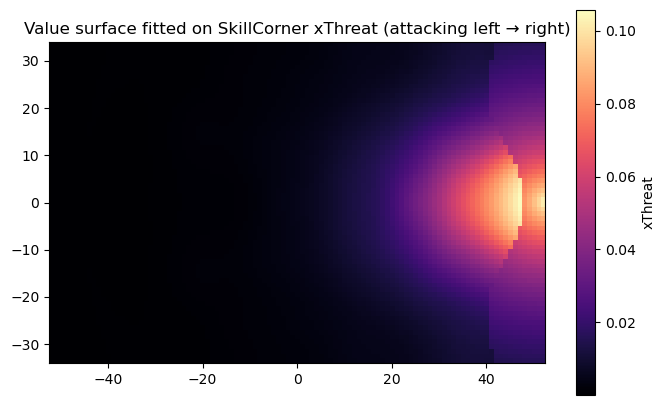

In [18]:
value_surface = fit_value_surface(events_all)
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(value_surface.z, origin="lower", extent=[-52.5, 52.5, -34, 34], cmap="magma")
ax.set_title("Value surface fitted on SkillCorner xThreat (attacking left → right)")
plt.colorbar(im, ax=ax, label="xThreat")
plt.savefig(FIG_DIR / "value_surface.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
def process_match(mid: int) -> dict:
    trk, meta = load_match(mid)
    grid = Grid(meta.pitch_length, meta.pitch_width)
    ctx = MatchContext(trk, meta, grid, value_surface(grid.points), ep, dict(zip(meta.players.player_id, meta.players.role)),
                       exclude=mid if CF_LEAVE_ONE_OUT else None,
                       coarse=Grid(105.0, 68.0, res=5.0))   # fixed so maps stack across matches
    ev = events_all[events_all.match_id == mid]
    runs = match_sk_runs(detect_movements(trk, meta, ev), ev)
    scored = pd.DataFrame([score_run(ctx, r) for r in runs.itertuples()], index=runs.index)
    runs = pd.concat([runs, scored], axis=1)
    occ = score_occupation(ctx, ev)
    passes = score_passes(ctx, ev)
    line, line_def = score_defensive_line(ctx)
    lag = step_lag(trk, meta)
    return dict(runs=runs, occupation=occ, passes=passes, line=line, line_def=line_def, lag=lag)
 
 
results = {}
for mid in match_ids:
    try:
        results[mid] = process_match(mid)
        r = results[mid]
        k = r["runs"].kind.value_counts()
        print(f"{mid}: {k.get('off_ball', 0)} off-ball runs, {k.get('carry', 0)} carries, {len(r['occupation'])} options, "
              f"{len(r['passes'])} passes, {len(r['line'])} line frames")
    except Exception as exc:          # keep going; report at the end
        print(f"{mid}: FAILED — {exc!r}")
 
RUNS = pd.concat([r["runs"] for r in results.values()], ignore_index=True)
OCC = pd.concat([r["occupation"] for r in results.values()], ignore_index=True)
PASSES = pd.concat([r["passes"] for r in results.values()], ignore_index=True)
LINE = pd.concat([r["line"] for r in results.values()], ignore_index=True)
LINE_DEF = pd.concat([r["line_def"] for r in results.values()], ignore_index=True)
LAG = pd.concat([r["lag"] for r in results.values()], ignore_index=True)
 
for name, df in dict(runs=RUNS.drop(columns=["path", "defence_map", "attack_map"]), occupation=OCC, passes=PASSES,
                     line=LINE, line_def=LINE_DEF, step_lag=LAG).items():
    df.to_csv(OUT_DIR / f"{name}.csv", index=False)
RUNS.to_pickle(OUT_DIR / "runs_full.pkl")

1925299: 1242 off-ball runs, 456 carries, 2715 options, 912 passes, 7238 line frames
1996435: 1374 off-ball runs, 410 carries, 2595 options, 877 passes, 6511 line frames


## 12. Space-creation taxonomy

Each run gets one value from each **independent** classifier, so types combine freely. Categories are learned from
the data where possible; SkillCorner's run types are kept as a candidate label set.

| Classifier | Method |
|---|---|
| Run direction | DTW distance between resampled run paths → hierarchical clustering (option 1) |
| Where space is created | PCA + k-means on the created-space map (option 2), in **both lenses** |
| Creator position | role group from the line-up |
| Creator location | start zone: third × channel |
| Run type | SkillCorner label where matched; k-NN on path features for the rest (options 4 & 5) |
| Ball type into the space | next teammate pass: through ball on the ground, over the top, switch, … |
| Body orientation | from pose data where available (Section 13) |

In [20]:
def dtw_matrix(A: np.ndarray, B: np.ndarray, chunk: int = 200) -> np.ndarray:
    """Pairwise DTW between path sets A (n, T, 2) and B (m, T, 2)."""
    n, m, T = len(A), len(B), A.shape[1]
    out = np.empty((n, m))
    for c in range(0, n, chunk):
        a = A[c:c + chunk]
        cost = np.linalg.norm(a[:, None, :, None, :] - B[None, :, None, :, :], axis=-1)   # (c, m, T, T)
        D = np.full((len(a), m, T + 1, T + 1), np.inf)
        D[:, :, 0, 0] = 0
        for i in range(1, T + 1):
            for j in range(1, T + 1):
                D[:, :, i, j] = cost[:, :, i - 1, j - 1] + np.minimum(np.minimum(D[:, :, i - 1, j], D[:, :, i, j - 1]),
                                                                      D[:, :, i - 1, j - 1])
        out[c:c + chunk] = D[:, :, T, T]
    return out


def choose_k(X, ks, precomputed=False, labels_fn=None):
    best = (None, -1, None)
    for k in ks:
        lab = labels_fn(k)
        if len(set(lab)) < 2:
            continue
        s = silhouette_score(X, lab, metric="precomputed" if precomputed else "euclidean")
        if s > best[1]:
            best = (k, s, lab)
    return best


def direction_label(dx, dy):
    ang = np.degrees(np.arctan2(dy, dx))
    side = "left" if dy > 0 else "right"
    if abs(ang) <= 30:
        return "forward"
    if abs(ang) >= 150:
        return "backward"
    if abs(ang) < 75:
        return f"forward-diagonal {side}"
    if abs(ang) > 105:
        return f"backward-diagonal {side}"
    return f"lateral {side}"


def classify_run_direction(runs: pd.DataFrame, n_fit: int = 1500, ks=range(4, 11)):
    rng = np.random.default_rng(RANDOM_STATE)
    paths = np.stack(runs.path.values)
    fit = rng.choice(len(runs), min(n_fit, len(runs)), replace=False)
    Dm = dtw_matrix(paths[fit], paths[fit])
    Dm = (Dm + Dm.T) / 2
    np.fill_diagonal(Dm, 0)
    Z = linkage(squareform(Dm, checks=False), "average")
    k, sil, lab = choose_k(Dm, ks, precomputed=True, labels_fn=lambda k: fcluster(Z, k, "maxclust"))
    medoids = []
    for c in np.unique(lab):
        members = np.flatnonzero(lab == c)
        medoids.append(fit[members[Dm[np.ix_(members, members)].sum(1).argmin()]])
    assign = dtw_matrix(paths, paths[medoids]).argmin(1)
    names = {}
    for c, mi in enumerate(medoids):
        end = paths[mi][-1]
        names[c] = f"D{c}: {direction_label(*end)} (~{np.linalg.norm(end):.0f} m)"
    print(f"Run direction: k={k}, silhouette={sil:.2f}")
    return pd.Series([names[a] for a in assign], index=runs.index), medoids


def zone_name(x, y):
    if np.isnan(x):
        return "none"
    third = "defensive third" if x < -17.5 else ("middle third" if x < 17.5 else "final third")
    ay = abs(y)
    lane = "central" if ay < 9.16 else ("half-space" if ay < 20.16 else "wide")
    side = "" if lane == "central" else (" left" if y > 0 else " right")
    return f"{lane}{side}, {third}"


def classify_space_maps(maps: np.ndarray, coarse: Grid, prefix: str, ks=range(4, 11)):
    """PCA + k-means on normalised created-space maps; clusters named by their centroid zone."""
    mass = maps.sum(1, keepdims=True)
    ok = mass[:, 0] > 1e-6
    X = maps[ok] / mass[ok]
    Xp = PCA(n_components=min(10, X.shape[1], len(X) - 1), random_state=RANDOM_STATE).fit_transform(X)
    k, sil, lab = choose_k(Xp, ks, labels_fn=lambda k: KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xp))
    names = {}
    for c in np.unique(lab):
        m = X[lab == c].mean(0)
        cx, cy = (m[:, None] * coarse.points).sum(0) / m.sum()
        names[c] = f"{prefix}{c}: {zone_name(cx, cy)}"
    out = np.full(len(maps), f"{prefix}-: no space created", dtype=object)
    out[ok] = [names[l] for l in lab]
    print(f"Space zone ({prefix}): k={k}, silhouette={sil:.2f}")
    return out


def classify_ball_type(runs: pd.DataFrame, events: pd.DataFrame, window: int = 20) -> pd.DataFrame:
    pp = events[(events.event_type == "player_possession") & (events.end_type == "pass")]
    by = {(m, t): g for (m, t), g in pp.groupby(["match_id", "team_id"])}
    out = []
    for r in runs.itertuples():
        g = by.get((r.match_id, r.team_id))
        hit = None
        if g is not None:
            # off-ball run: the ball played by a teammate; carry: the carrier's own pass at the end of the carry
            who = (g.player_id != r.player_id) if r.kind == "off_ball" else (g.player_id == r.player_id)
            c = g[(g.frame_end >= r.frame_start) & (g.frame_end <= r.frame_end + window) & who]
            if len(c):
                hit = c.iloc[0]
        if hit is None:
            out.append(("none", False))
            continue
        ty = hit.player_targeted_y_reception if pd.notna(hit.player_targeted_y_reception) else hit.player_targeted_y_pass
        dy = abs((ty if pd.notna(ty) else hit.y_end) - hit.y_end)
        if hit.furthest_line_break == "last":
            kind = "over the top" if hit.high_pass is True else "through ball on the ground"
        elif dy > 25:
            kind = "switch"
        elif hit.high_pass is True:
            kind = "lofted"
        elif hit.pass_range == "short":
            kind = "short combination"
        elif hit.furthest_line_break in ("first", "second_last"):
            kind = "line-breaking ground pass"
        else:
            kind = "other ground pass"
        out.append((kind, hit.player_targeted_id == r.player_id))
    return pd.DataFrame(out, index=runs.index, columns=["ball_type", "ball_to_runner"])


def run_type_classifier(runs: pd.DataFrame):
    """k-NN on path + start location + role, trained on SkillCorner-labelled runs, applied to the rest."""
    feats = np.c_[np.stack(runs.path.values).reshape(len(runs), -1), runs[["x_start", "y_start"]].values,
                  pd.get_dummies(runs.role_group).values.astype(float)]
    lab = runs.sk_event_subtype
    train = lab.notna().values
    if train.sum() < 30:
        print(f"Only {train.sum()} SkillCorner-labelled runs: k-NN skipped, unmatched runs left unlabelled")
        return lab.fillna("unlabelled"), np.where(train, "skillcorner", "none"), pd.Series(np.nan, index=runs.index), np.nan
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights="distance"))
    acc = cross_val_score(model, feats[train], lab[train].astype(str), cv=5).mean() if train.sum() > 50 else np.nan
    model.fit(feats[train], lab[train].astype(str))
    pred = pd.Series(model.predict(feats), index=runs.index)
    conf = pd.Series(model.predict_proba(feats).max(1), index=runs.index)
    print(f"Run-type k-NN trained on {train.sum()} SkillCorner-labelled runs; 5-fold accuracy: "
          + (f"{acc:.1%}" if pd.notna(acc) else "n/a (too few labels)"))
    final = lab.where(lab.notna(), pred)
    source = np.where(train, "skillcorner", "knn")
    return final, source, conf, acc

In [21]:
RUNS["role_group"] = RUNS.role.map(ROLE_GROUP).fillna("OTHER")
RUNS["creator_location"] = [zone_name(x, y) for x, y in zip(RUNS.x_start, RUNS.y_start)]
RUNS["run_direction"], DIR_MEDOIDS = classify_run_direction(RUNS)
COARSE = Grid(105.0, 68.0, res=5.0)
RUNS["space_zone_defence"] = classify_space_maps(np.stack(RUNS.defence_map.values), COARSE, "S")
RUNS["space_zone_attack"] = classify_space_maps(np.stack(RUNS.attack_map.values), COARSE, "A")
RUNS = RUNS.join(classify_ball_type(RUNS, events_all))
RUNS["run_type"], RUNS["run_type_source"], RUNS["run_type_conf"], RUNTYPE_ACC = run_type_classifier(RUNS)
is_carry = RUNS.kind == "carry"
RUNS.loc[is_carry, "run_type"] = "carry (on ball)"
RUNS.loc[is_carry, "run_type_source"] = "carry"
RUNS.loc[is_carry, "run_type_conf"] = np.nan
 
 
def cosine_rows(A, B):
    return (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1) + 1e-12)
 
 
RUNS["lens_similarity"] = cosine_rows(np.stack(RUNS.defence_map.values), np.stack(RUNS.attack_map.values))
RUNS["lens_value_gap"] = RUNS.attack_only_value - RUNS.created.clip(lower=0)
 
TAXONOMY = ["kind", "run_direction", "space_zone_defence", "space_zone_attack", "role_group", "creator_location", "run_type",
            "ball_type"]
display(RUNS[TAXONOMY].describe().T)

Run direction: k=4, silhouette=0.53


c:\Users\bchm5\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\bchm5\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

Space zone (S): k=10, silhouette=0.34
Space zone (A): k=10, silhouette=0.38
Run-type k-NN trained on 885 SkillCorner-labelled runs; 5-fold accuracy: 49.7%


,count,unique,top,freq
kind,3482,2,off_ball,2616
run_direction,3482,4,D2: forward (~5 m),3109
space_zone_defence,3482,11,S-: no space created,1016
space_zone_attack,3482,11,"A0: central, middle third",1425
role_group,3482,8,W,805
creator_location,3482,15,"central, middle third",583
run_type,3482,11,carry (on ball),866
ball_type,3482,8,none,1157


### 12.1 Two lenses: designed space vs real space

`lens_similarity` compares the attacking-only map (where the run *should* open space if there were no defenders)
with the defence-aware map (where space actually opened). Low similarity = the defence closed or redirected the
designed space. The cross-tab shows which designed zones turn into which real zones.

In [22]:
bu = RUNS[RUNS.phase.isin(BUILDUP_PHASES)]
display(pd.crosstab(bu.space_zone_attack, bu.space_zone_defence, normalize="index").round(2))
display(bu.groupby("run_type")[["created", "attack_only_value", "lens_similarity"]].mean().sort_values("created",
                                                                                                      ascending=False))

space_zone_defence,S-: no space created,"S0: half-space right, final third","S1: central, middle third","S2: central, final third","S3: central, middle third","S4: central, final third","S5: central, middle third","S6: central, final third","S7: half-space right, final third","S8: central, middle third","S9: half-space right, middle third"
space_zone_attack,,,,,,,,,,,
A-: no space created,0.37,0.00,0.30,0.02,0.12,0.00,0.06,0.00,0.01,0.07,0.05
"A0: central, middle third",0.34,0.02,0.40,0.01,0.05,0.00,0.07,0.00,0.00,0.07,0.04
"A1: central, final third",0.26,0.00,0.15,0.11,0.00,0.15,0.00,0.30,0.04,0.00,0.00
"A2: central, middle third",0.28,0.08,0.06,0.08,0.06,0.00,0.20,0.00,0.02,0.00,0.23
"A3: central, final third",0.23,0.09,0.06,0.09,0.00,0.20,0.00,0.20,0.14,0.00,0.00
"A4: half-space right, final third",0.15,0.30,0.08,0.17,0.00,0.06,0.04,0.00,0.15,0.00,0.06
"A5: central, final third",0.23,0.12,0.12,0.21,0.00,0.04,0.10,0.06,0.08,0.00,0.02
"A6: central, final third",0.14,0.00,0.19,0.14,0.00,0.00,0.00,0.48,0.05,0.00,0.00
"A7: central, middle third",0.25,0.00,0.12,0.07,0.01,0.01,0.36,0.00,0.01,0.01,0.17


,created,attack_only_value,lens_similarity
run_type,,,
underlap,0.103844,0.929198,0.233211
pulling_half_space,0.083469,0.211110,0.269513
carry (on ball),0.033446,0.114130,0.152958
overlap,0.025676,0.063232,0.093620
behind,0.017987,0.268211,0.308638
support,0.016889,0.288195,0.165642
pulling_wide,0.014852,0.153877,0.198763
run_ahead_of_the_ball,0.007589,0.263045,0.160061
dropping_off,0.001529,0.037721,0.043008


### 12.2 Which space-creation types work, and against what?

Outcome per run type, split by the defending team's out-of-possession phase (high press vs mid/low block).
These are exploratory with 20 matches.

In [23]:
oop = (events_all[["match_id", "frame_start", "team_out_of_possession_phase_type"]].dropna()
       .drop_duplicates(["match_id", "frame_start"]))
bu = pd.merge_asof(bu.sort_values("frame_start"), oop.sort_values("frame_start"), on="frame_start",
                   by="match_id", direction="backward")
display(bu.pivot_table(index="run_type", columns="team_out_of_possession_phase_type", values="created",
                       aggfunc="mean").round(3))

team_out_of_possession_phase_type,chaotic,defending_direct,defending_quick_break,high_block,low_block,medium_block
run_type,,,,,,
behind,NaN,-0.005,NaN,-0.002,0.077,0.012
carry (on ball),NaN,-0.002,NaN,0.011,0.118,0.026
coming_short,-0.038,-0.012,NaN,0.004,-0.010,-0.009
cross_receiver,NaN,-0.014,NaN,0.037,-0.007,-0.032
dropping_off,0.008,0.001,NaN,0.002,0.033,-0.006
overlap,-0.008,NaN,NaN,0.000,0.044,0.005
pulling_half_space,NaN,-0.001,NaN,-0.001,0.358,0.046
pulling_wide,-0.003,0.003,NaN,0.006,0.055,0.020
run_ahead_of_the_ball,-0.042,0.031,0.000,-0.004,0.008,0.010


## 13. Body orientation (pose)

Pose is the Cup's headline new data, so it is treated as a core component:

* **Shoulder heading** (SkillCorner's gated method: both shoulders present, plausible width, error ≤ 15 cm) and
  **head yaw** (nose relative to the ear midpoint), both turned into the attacking frame.
* **Orientation class** relative to the opponent goal: facing forward (< 45°), side-on / open (45–135°),
  back to goal (> 135°).
* **Scanning** before a pass: head turns of > 30° relative to the torso in the 2 s before release.
* Joined to runs (creator at run start, dragged defenders at run end), occupations and passes.

Only two matches have pose (1925299, 1996435). Download them from the Hugging Face Hub
(`SkillCorner/opendata-bodypose`, `raw/{match_id}.jsonl.zip`) into `DATA_DIR/bodypose/`. Without them the
notebook falls back to the 12-second sample phase so the code path still runs.

In [24]:
POSE_FPS = 25
POSE_FILES = {1925299: DATA_DIR / "bodypose" / "1925299.jsonl.zip", 1996435: DATA_DIR / "bodypose" / "1996435.jsonl.zip"}
POSE_SAMPLE = DATA_DIR / "bodypose" / "sample_1925299_phase406.jsonl.gz"


def iter_pose(path: Path):
    if path.suffix == ".gz":
        with gzip.open(path, "rt") as fh:
            for line in fh:
                yield json.loads(line)
    elif path.suffix == ".zip":
        with zipfile.ZipFile(path) as z:
            with z.open(z.namelist()[0]) as fh:
                for line in fh:
                    yield json.loads(line)


def wrap180(a):
    return (np.asarray(a) + 180) % 360 - 180


def pose_rows(path: Path, meta: MatchMeta, wanted_10fps: set | None = None, max_err_cm: float = 15.0) -> pd.DataFrame:
    team_of = dict(zip(meta.players.player_id, meta.players.team_id))
    rows = []
    for rec in iter_pose(path):
        f10 = math.floor(rec["frame"] * FPS / POSE_FPS + 0.5)
        if wanted_10fps is not None and f10 not in wanted_10fps:
            continue
        for p in rec.get("player_data") or []:
            J = p.get("joints")
            if not J or "lShoulder" not in J or "rShoulder" not in J:
                continue
            (lx, ly, _), (rx, ry, _) = J["lShoulder"]["xyz"], J["rShoulder"]["xyz"]
            width = math.hypot(rx - lx, ry - ly)
            err = max(J["lShoulder"].get("p90_mae_cm") or 99, J["rShoulder"].get("p90_mae_cm") or 99)
            if not (0.15 <= width <= 0.60) or err > max_err_cm:
                continue
            shoulder = math.degrees(math.atan2(rx - lx, -(ry - ly)))      # left→right axis rotated +90°
            head = np.nan
            if all(k in J for k in ("nose", "lEar", "rEar")):
                ex, ey = (J["lEar"]["xyz"][0] + J["rEar"]["xyz"][0]) / 2, (J["lEar"]["xyz"][1] + J["rEar"]["xyz"][1]) / 2
                head = math.degrees(math.atan2(J["nose"]["xyz"][1] - ey, J["nose"]["xyz"][0] - ex))
            team = team_of.get(p["player_id"])
            s = meta.direction.get((team, rec["period"]), 1)
            flip = 0 if s == 1 else 180
            rows.append(dict(frame25=rec["frame"], frame=f10, period=rec["period"], player_id=p["player_id"],
                             team_id=team, shoulder_deg=float(wrap180(shoulder + flip)),
                             head_deg=float(wrap180(head + flip)) if not np.isnan(head) else np.nan, err_cm=err))
    df = pd.DataFrame(rows)
    if len(df):
        df["head_rel_deg"] = wrap180(df.head_deg - df.shoulder_deg)
        a = df.shoulder_deg.abs()
        df["orientation"] = np.where(a < 45, "facing forward", np.where(a <= 135, "side-on / open", "back to goal"))
    return df


def scans_before(pose: pd.DataFrame, player_id: int, frame: int, secs: float = 2.0, thr: float = 30.0) -> float:
    w = pose[(pose.player_id == player_id) & (pose.frame <= frame) & (pose.frame > frame - secs * FPS)]
    if len(w) < 10:
        return np.nan
    rel = w.sort_values("frame25").head_rel_deg.rolling(5, center=True, min_periods=1).median().values
    out = np.abs(rel) > thr
    return float(np.sum(out[1:] & ~out[:-1]))


def orientation_at(pose: pd.DataFrame, player_id, frame, tol: int = 2):
    w = pose[(pose.player_id == player_id) & ((pose.frame - frame).abs() <= tol)]
    if not len(w):
        return np.nan, None
    r = w.iloc[(w.frame - frame).abs().argmin()]
    return r.shoulder_deg, r.orientation


pose_frames = []
for mid, path in POSE_FILES.items():
    if mid not in metas:
        continue
    if not path.exists():
        if mid == 1925299 and POSE_SAMPLE.exists():
            print(f"{path.name} not found -> using the sample phase for {mid}")
            path = POSE_SAMPLE
        else:
            print(f"{path.name} not found -> skipping pose for {mid}")
            continue
    r = RUNS[RUNS.match_id == mid]
    p = PASSES[PASSES.match_id == mid]
    wanted = set(r.frame_start) | set(r.frame_end) | {f - k for f in p.frame_pass for k in range(0, 2 * FPS + 1)}
    pose_frames.append(pose_rows(path, metas[mid], wanted).assign(match_id=mid))
POSE = pd.concat(pose_frames, ignore_index=True) if pose_frames else pd.DataFrame()
print(f"{len(POSE):,} reliable player-frames with pose")

1925299.jsonl.zip not found -> using the sample phase for 1925299
1996435.jsonl.zip not found -> skipping pose for 1996435
989 reliable player-frames with pose


In [25]:
if len(POSE):
    pr = RUNS[RUNS.match_id.isin(POSE.match_id.unique())].copy()
    o = [orientation_at(POSE[POSE.match_id == r.match_id], r.player_id, r.frame_start) for r in pr.itertuples()]
    pr["orient_start_deg"], pr["orientation_start"] = zip(*o) if o else ([], [])
    o = [orientation_at(POSE[POSE.match_id == r.match_id], r.player_id, r.frame_end) for r in pr.itertuples()]
    pr["orient_end_deg"], pr["orientation_end"] = zip(*o) if o else ([], [])
    RUNS = RUNS.join(pr[["orient_start_deg", "orientation_start", "orient_end_deg", "orientation_end"]])
    pp_ = PASSES[PASSES.match_id.isin(POSE.match_id.unique())].copy()
    pp_["scans_2s"] = [scans_before(POSE[POSE.match_id == r.match_id], r.player_id, r.frame_pass) for r in pp_.itertuples()]
    pp_["passer_orient_deg"] = [orientation_at(POSE[POSE.match_id == r.match_id], r.player_id, r.frame_pass)[0]
                                for r in pp_.itertuples()]
    PASSES = PASSES.join(pp_[["scans_2s", "passer_orient_deg"]])
    print("Body orientation at run start vs space created (pose matches):")
    display(RUNS.dropna(subset=["orientation_start"]).groupby("orientation_start")[["created", "attack_only_value"]]
            .agg(["mean", "count"]).round(3))
    print("Do early passers scan more?")
    q = PASSES.dropna(subset=["scans_2s", "lead_s"])
    if len(q) > 10:
        print(spearmanr(q.scans_2s, q.lead_s))

Body orientation at run start vs space created (pose matches):


created       attack_only_value      
                     mean count              mean count
orientation_start                                      
facing forward     -0.135     1             0.022     1
side-on / open      0.308     1             7.325     1

Do early passers scan more?


## 14. Validation against SkillCorner Game Intelligence

In [26]:
sk_runs = events_all[events_all.event_type == "off_ball_run"]
matched_ids = set(RUNS.sk_event_id.dropna())
val = {
    "SkillCorner runs found by tracking detection (recall)": len(matched_ids) / max(len(sk_runs), 1),
    "Tracking off-ball runs that match a SkillCorner run": RUNS[RUNS.kind == "off_ball"].sk_event_id.notna().mean(),
}
m = RUNS.dropna(subset=["sk_xthreat"])
if len(m) > 10:
    val["Spearman: created space vs SkillCorner run xThreat"] = spearmanr(m.created, m.sk_xthreat.astype(float))[0]
    val["Mean created, SK dangerous runs"] = m[m.sk_dangerous == True].created.mean()
    val["Mean created, SK non-dangerous runs"] = m[m.sk_dangerous == False].created.mean()

# Defensive line vs SkillCorner's last defensive line
skl = (events_all[events_all.event_type == "player_possession"]
       [["match_id", "frame_start", "team_id", "last_defensive_line_x_start"]].dropna()
       .rename(columns={"frame_start": "frame", "team_id": "team_att"}).sort_values("frame"))
lv = pd.merge_asof(LINE.sort_values("frame"), skl, on="frame", by=["match_id", "team_att"], tolerance=3,
                   direction="nearest").dropna(subset=["last_defensive_line_x_start"])
if len(lv):
    val["Line height: MAE vs SkillCorner (m)"] = (lv.line_x - lv.last_defensive_line_x_start).abs().mean()
    val["Line height: correlation with SkillCorner"] = lv[["line_x", "last_defensive_line_x_start"]].corr().iat[0, 1]

# Lead time vs how long SkillCorner's passing option had existed
opt = events_all[events_all.event_type == "passing_option"][["event_id", "frame_start"]].rename(
    columns={"event_id": "sk_option_event", "frame_start": "option_start"})
lt = PASSES.merge(opt, on="sk_option_event", how="inner").dropna(subset=["lead_s"])
if len(lt) > 10:
    lt["option_age_s"] = (lt.frame_pass - lt.option_start) / FPS
    val["Spearman: lead time vs SK option age at release"] = spearmanr(lt.lead_s, lt.option_age_s)[0]
val["Run-type k-NN accuracy vs SkillCorner"] = RUNTYPE_ACC
display(pd.Series(val).round(3).to_frame("value"))

,value
SkillCorner runs found by tracking detection (recall),0.495
Tracking off-ball runs that match a SkillCorner run,0.338
Spearman: created space vs SkillCorner run xThreat,-0.024
"Mean created, SK dangerous runs",0.030
"Mean created, SK non-dangerous runs",0.016
Line height: MAE vs SkillCorner (m),0.398
Line height: correlation with SkillCorner,0.999
Spearman: lead time vs SK option age at release,-0.063
Run-type k-NN accuracy vs SkillCorner,0.497


In [27]:
print("Does data quality change the creator metric? (mean created by runner detection rate)")
display(RUNS.groupby(pd.cut(RUNS.runner_detected, [0, .25, .5, .75, 1.0], include_lowest=True))
        .created.agg(["mean", "count"]).round(4))

Does data quality change the creator metric? (mean created by runner detection rate)


C:\Users\bchm5\AppData\Local\Temp\ipykernel_22548\3260332289.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(RUNS.groupby(pd.cut(RUNS.runner_detected, [0, .25, .5, .75, 1.0], include_lowest=True))


,mean,count
runner_detected,,
"(-0.001, 0.25]",0.0207,316
"(0.25, 0.5]",0.0093,142
"(0.5, 0.75]",-0.0119,151
"(0.75, 1.0]",0.0263,2873


## 15. Leaderboards and team comparison

Build-up phases only, reliable rows only (runner and dragged defenders mostly on camera), per 30 minutes of the
player's team being in possession. Sample size is fixed by the competition, so a minimum-minutes cut is applied
and team comparisons are exploratory.

In [28]:
mins = players_all.groupby("player_id").agg(name=("name", "first"), team_id=("team_id", "first"),
                                             role=("role", lambda s: s.mode().iat[0]),
                                             minutes_tip=("minutes_tip", "sum"), matches=("match_id", "nunique"))
mins["team"] = mins.team_id.map(team_names)
 
 
def per30(s):
    return s / mins.minutes_tip.reindex(s.index) * 30
 
 
R = RUNS[RUNS.phase.isin(BUILDUP_PHASES) & (RUNS.runner_detected >= 0.5)
         & ~(RUNS.dragged_detected < 0.5)]
RO, RC = R[R.kind == "off_ball"], R[R.kind == "carry"]
creator = pd.DataFrame({"runs_p30": per30(RO.groupby("player_id").size()),
                        "created_p30": per30(RO.groupby("player_id").created.sum()),
                        "created_per_run": RO.groupby("player_id").created.mean(),
                        "drag_rate": RO.groupby("player_id").n_dragged.apply(lambda s: (s > 0).mean())})
carrier = pd.DataFrame({"carries_p30": per30(RC.groupby("player_id").size()),
                        "carry_created_p30": per30(RC.groupby("player_id").created.sum()),
                        "created_per_carry": RC.groupby("player_id").created.mean(),
                        "draw_rate": RC.groupby("player_id").n_dragged.apply(lambda s: (s > 0).mean())})
 
O = OCC[OCC.phase.isin(BUILDUP_PHASES) & OCC.detected]
occupier = pd.DataFrame({"occupy_value_p30": per30(O.groupby("player_id").occupy_value.sum()),
                         "in_created_p30": per30(O.groupby("player_id").in_created_space.sum()),
                         "median_latency_s": O[O.in_created_space].groupby("player_id").latency_s.median(),
                         "arrival_speed": O[O.in_created_space].groupby("player_id").arrival_speed.mean()})
 
F = PASSES[PASSES.phase.isin(BUILDUP_PHASES)]
F_space = F[F.opened | F.into_created_space | F.sk_line_break]
feeder = pd.DataFrame({"vision_p30": per30(F.groupby("player_id").vision_credit.sum()),
                       "space_attempts_p30": per30(F_space.groupby("player_id").size()),
                       "mean_lead_s": F_space.groupby("player_id").lead_s.mean(),
                       "completion_into_space": F_space.groupby("player_id").completed.mean(),
                       "precision": F_space.groupby("player_id").precision.mean()})
 
 
def z(s):
    return (s - s.mean()) / s.std()
 
 
board = mins.join([creator, carrier, occupier, feeder])
board = board[board.minutes_tip >= MIN_TIP_MINUTES]
print(f"{len(board)} players with ≥ {MIN_TIP_MINUTES:.0f} minutes of their team in possession")
board["execution"] = (z(board.completion_into_space) + z(board.precision)) / 2
board["feeder_score"] = W_VISION * z(board.vision_p30) + W_EXEC * z(board.execution)
board.to_csv(OUT_DIR / "player_leaderboard.csv")
 
cols = ["name", "team", "role", "minutes_tip"]
print("Top space creators — off-ball runs"); display(board.sort_values("created_p30", ascending=False)[cols + list(creator.columns)].head(15).round(3))
print("Top space creators — carrying the ball")
display(board.sort_values("carry_created_p30", ascending=False)[cols + list(carrier.columns)].head(15).round(3))
print("Top space occupiers"); display(board.sort_values("occupy_value_p30", ascending=False)[cols + list(occupier.columns)].head(15).round(3))
print("Top space feeders (vision weighted above execution)")
display(board.sort_values("feeder_score", ascending=False)[cols + list(feeder.columns) + ["feeder_score"]].head(15).round(3))

0 players with ≥ 45 minutes of their team in possession
Top space creators — off-ball runs


,name,team,role,minutes_tip,runs_p30,created_p30,created_per_run,drag_rate
player_id,,,,,,,,


Top space creators — carrying the ball


,name,team,role,minutes_tip,carries_p30,carry_created_p30,created_per_carry,draw_rate
player_id,,,,,,,,


Top space occupiers


,name,team,role,minutes_tip,occupy_value_p30,in_created_p30,median_latency_s,arrival_speed
player_id,,,,,,,,


Top space feeders (vision weighted above execution)


,name,team,role,minutes_tip,vision_p30,space_attempts_p30,mean_lead_s,completion_into_space,precision,feeder_score
player_id,,,,,,,,,,


In [29]:
team_tip = players_all.groupby(["match_id", "team_id"]).minutes_tip.max().groupby("team_id").sum()
line_team = LINE[LINE.phase.isin(BUILDUP_PHASES)].groupby("team_def").agg(
    line_depth=("depth", "mean"), spread_stepping_up=("spread", lambda s: s[LINE.loc[s.index, "stepping_up"]].mean()),
    gk_gap=("gk_gap", "mean"), space_behind=("space_behind", "mean"), conceded_by_line=("conceded_by_line", "mean"))
teams = pd.DataFrame({
    "created_offball_p30": RO.groupby("team_id").created.sum() / team_tip * 30,
    "created_carry_p30": RC.groupby("team_id").created.sum() / team_tip * 30,
    "occupy_value_p30": O.groupby("team_id").occupy_value.sum() / team_tip * 30,
    "vision_p30": F.groupby("team_id").vision_credit.sum() / team_tip * 30,
    "completion_into_space": F_space.groupby("team_id").completed.mean(),
}).join(line_team.add_prefix("def_"))
teams.index = teams.index.map(team_names)
teams.to_csv(OUT_DIR / "team_comparison.csv")
display(teams.sort_values("created_offball_p30", ascending=False).round(3))

,created_offball_p30,created_carry_p30,occupy_value_p30,vision_p30,completion_into_space,def_line_depth,def_spread_stepping_up,def_gk_gap,def_space_behind,def_conceded_by_line
team_id,,,,,,,,,,
Sydney FC,3.627,6.147,0.035,0.021,0.928,41.836,2.547,25.183,36.519,0.365
Adelaide United,3.002,9.259,0.038,0.012,0.916,39.807,3.476,24.843,35.529,0.491
Perth Glory,2.268,1.868,0.016,0.009,0.907,37.008,1.793,23.301,34.650,0.299
Brisbane FC,0.169,1.416,0.014,0.009,0.942,40.552,2.158,24.692,35.717,0.490


In [30]:
late = (LAG.groupby("player_id").agg(lag_s=("lag_s", "mean"), sync_r=("sync_r", "mean"), matches=("match_id", "nunique"))
        .join(LINE_DEF.groupby("player_id").conceded_share.sum().rename("conceded_by_line"))
        .join(mins[["name", "team", "role"]]))
print("Back-line synchrony: late steppers and space conceded by not holding the line")
display(late.sort_values("conceded_by_line", ascending=False).head(15).round(3))

Back-line synchrony: late steppers and space conceded by not holding the line


,lag_s,sync_r,matches,conceded_by_line,name,team,role
player_id,,,,,,,
809759,0.0,0.891,1,806.207,P. Kikianis,Adelaide United,LCB
26766,-0.1,0.892,1,729.384,B. Vriends,Adelaide United,RCB
809166,0.0,0.888,1,654.604,A. Lebib,Perth Glory,RCB
965697,-0.2,0.915,1,553.981,L. Herrington,Brisbane FC,RCB
51644,-0.1,0.890,1,441.223,R. Grant,Sydney FC,RCB
998256,-0.1,0.905,1,420.086,K. Shaw,Sydney FC,LCB
560989,-0.2,0.883,1,303.321,T. Mrčela,Perth Glory,LCB
69111,-0.1,0.885,1,238.604,H. Bility,Brisbane FC,LCB
11897,0.2,0.791,1,138.209,J. Risdon,Perth Glory,RB


## 16. Visuals for case studies

Each case shows: actual pitch control, the **created** map (defence-aware lens) with dragged defenders and their
expected spots, and the **attacking-only** map. The title carries the period and match clock so the moment can be
found in broadcast footage and shown side by side. `animate_run` writes a GIF of the same moment.

In [31]:
from matplotlib.lines import Line2D
 
KIND_STYLE = {"off_ball": dict(color="#d62728", label="off-ball run"),
              "carry": dict(color="#ff7f0e", label="carry (on ball)")}
ATT_C, DEF_C, BEN_C = "#d62728", "#1f77b4", "#2ca02c"
 
# Who benefits from the space? Arrival-time model (Spearman-style): each player reacts for 0.7 s along his current
# velocity, then runs straight at 7 m/s. A teammate's chance of getting to a cell first is a logistic of how much
# sooner he arrives than the quickest defender.
REACTION_S, VMAX, ARRIVAL_SIGMA = 0.7, 7.0, 0.45
 
 
def arrival_times(xy, vel, points):
    p = xy + vel * REACTION_S
    return REACTION_S + np.linalg.norm(points[None] - p[:, None], axis=-1) / VMAX
 
 
def find_beneficiary(ctx, run, i, created) -> dict | None:
    """Teammate who gains most from the created space: Σ (space created × value × chance he gets there first)."""
    trk, pts = ctx.trk, ctx.grid.points
    st = frame_state(trk, i, run.team_id)
    att = np.array([k for k in st["att"] if trk.player_ids[k] != run.player_id
                    and ctx.role.get(trk.player_ids[k]) != "GK"])
    gain = np.clip(created, 0, None) * ctx.value_grid
    if len(att) == 0 or gain.sum() <= 0:
        return None
    P, V = st["pos"], st["vel"]
    t_att = arrival_times(P[att], V[att], pts)
    t_def = arrival_times(P[st["dfn"]], V[st["dfn"]], pts).min(0)
    ease = 1 / (1 + np.exp(-(t_def - t_att) / ARRIVAL_SIGMA))          # (teammates, cells)
    benefit = (ease * gain).sum(1) * ctx.grid.cell_area
    k = int(benefit.argmax())
    c = int(np.argmax(ease[k] * gain))
    ranking = pd.DataFrame({"player_id": trk.player_ids[att], "benefit": benefit,
                            "share": benefit / max(benefit.sum(), 1e-12)}).sort_values("benefit", ascending=False)
    ranking["name"] = ranking.player_id.map(mins["name"])
    return dict(col=int(att[k]), player_id=int(trk.player_ids[att[k]]), name=mins["name"].get(trk.player_ids[att[k]], ""),
                target=pts[c], benefit=float(benefit[k]), share=float(benefit[k] / benefit.sum()),
                time_s=float(t_att[k, c]), ease=float(ease[k, c]), dist_m=float(np.linalg.norm(pts[c] - P[att[k]])),
                ranking=ranking)
 
 
def draw_pitch(ax, L=105, W=68, color="#999"):
    ax.plot([-L / 2, L / 2, L / 2, -L / 2, -L / 2], [-W / 2, -W / 2, W / 2, W / 2, -W / 2], color=color, lw=1)
    ax.plot([0, 0], [-W / 2, W / 2], color=color, lw=1)
    ax.add_patch(plt.Circle((0, 0), 9.15, fill=False, color=color, lw=1))
    for s in (-1, 1):
        ax.plot([s * L / 2, s * (L / 2 - 16.5), s * (L / 2 - 16.5), s * L / 2], [-20.16, -20.16, 20.16, 20.16], color=color, lw=1)
        ax.plot([s * L / 2, s * (L / 2 - 5.5), s * (L / 2 - 5.5), s * L / 2], [-9.16, -9.16, 9.16, 9.16], color=color, lw=1)
    ax.set_xlim(-L / 2 - 2, L / 2 + 2); ax.set_ylim(-W / 2 - 2, W / 2 + 2); ax.set_aspect("equal"); ax.axis("off")
 
 
def match_clock(trk, i):
    p = trk.period[i]
    start = trk.frames[trk.period == p].min()
    secs = (trk.frames[i] - start) / FPS + (45 * 60 if p == 2 else 0)
    return f"P{p} {int(secs // 60):02d}:{int(secs % 60):02d}"
 
 
def build_ctx(mid):
    trk, meta = load_match(mid)
    grid = Grid(meta.pitch_length, meta.pitch_width)
    return MatchContext(trk, meta, grid, value_surface(grid.points), ep, dict(zip(meta.players.player_id, meta.players.role)),
                        exclude=mid if CF_LEAVE_ONE_OUT else None, coarse=COARSE)
 
 
def run_scene(ctx, run, i, with_created=False):
    """Positions, teammates' pitch control and dragged-defender arrows at index i, in the attacking frame."""
    trk, g = ctx.trk, ctx.grid
    st = frame_state(trk, i, run.team_id)
    j = int(np.flatnonzero(trk.player_ids == run.player_id)[0])
    att = np.array([k for k in st["att"] if k != j])
    P, V, ball = st["pos"], st["vel"], st["ball"]
    pc = pitch_control(P[att], V[att], P[st["dfn"]], V[st["dfn"]], ball, g.points)
    drag_cols = [k for k in st["dfn"] if trk.player_ids[k] in set(run.dragged_ids)]
    exp = ctx.expected(drag_cols, "out", ball, trk.phase[i]) if drag_cols else np.zeros((0, 2))
    a = int(run.idx_start)
    trail = trk.pos[a:i + 1, j] * st["sign"] if i >= a else np.zeros((0, 2))
    scene = dict(P=P, att=st["att"], dfn=st["dfn"], ball=ball, runner=P[j], pc=pc, trail=trail,
                 drag_now=P[drag_cols] if drag_cols else np.zeros((0, 2)), drag_exp=exp)
    if with_created and drag_cols:
        Dr, Dv = P[st["dfn"]].copy(), V[st["dfn"]].copy()
        sel = np.isin(st["dfn"], drag_cols)
        Dr[sel], Dv[sel] = exp, 0
        scene["created"] = pc - pitch_control(P[att], V[att], Dr, Dv, ball, g.points)
    return scene
 
 
def draw_beneficiary(ax, pos, ben):
    """Green ring on the teammate who benefits most, and an arrow to the best spot in the space opened for him."""
    ax.scatter(*pos, s=260, facecolors="none", edgecolors=BEN_C, lw=2.2, zorder=5)
    ax.scatter(*ben["target"], marker="*", s=260, c=BEN_C, edgecolors="white", lw=.8, zorder=6)
    ax.annotate("", xy=ben["target"], xytext=pos, zorder=6,
                arrowprops=dict(arrowstyle="-|>", color=BEN_C, lw=2.2, ls="--", shrinkA=8, shrinkB=8))
    ax.annotate(ben["name"], pos, xytext=(0, 13), textcoords="offset points", ha="center", color=BEN_C, fontsize=8,
                weight="bold", zorder=7, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=.7))
 
 
def draw_scene(ax, scene, run, show_arrows=True):
    """Players, runner ring, path and the 'pulled from → ended up' arrows for dragged/drawn defenders."""
    style = KIND_STYLE[run.kind]
    ax.scatter(*scene["P"][scene["att"]].T, c=ATT_C, s=45, zorder=4, edgecolors="white", lw=.5)
    ax.scatter(*scene["P"][scene["dfn"]].T, c=DEF_C, s=45, zorder=4, edgecolors="white", lw=.5)
    if len(scene["trail"]) > 1:
        ax.plot(*scene["trail"].T, c=style["color"], lw=2.5, zorder=3, ls="-" if run.kind == "carry" else "--")
    ax.scatter(*scene["runner"], s=260, facecolors="none", edgecolors="black", lw=2, zorder=5)
    ax.scatter(*scene["ball"], c="black", s=22, zorder=6)
    if show_arrows:
        for e, now in zip(scene["drag_exp"], scene["drag_now"]):
            if np.isnan(e[0]):
                continue
            ax.scatter(*e, s=60, facecolors="none", edgecolors=DEF_C, lw=1.5, zorder=4)
            ax.annotate("", xy=now, xytext=e, zorder=5,
                        arrowprops=dict(arrowstyle="-|>", color=DEF_C, lw=1.8, shrinkA=4, shrinkB=5))
 
 
def legend_handles(run):
    style = KIND_STYLE[run.kind]
    pulled = "pulled by the run" if run.kind == "off_ball" else "drawn by the carrier"
    return [Line2D([], [], marker="o", ls="", color=ATT_C, label="team in possession (attacking →)"),
            Line2D([], [], marker="o", ls="", color=DEF_C, label="defending team"),
            Line2D([], [], marker="o", ls="", mfc="none", mec="black", mew=2, ms=11,
                   label="the runner" if run.kind == "off_ball" else "the ball carrier"),
            Line2D([], [], color=style["color"], lw=2.5, ls="-" if run.kind == "carry" else "--", label=f"path of the {style['label']}"),
            Line2D([], [], marker="o", ls="", mfc="none", mec=DEF_C, ms=8, label="defender's expected spot"),
            Line2D([], [], color=DEF_C, marker=">", lw=1.8, label=f"defender {pulled}: expected spot → where he ended up"),
            Line2D([], [], marker="o", ls="", mfc="none", mec=BEN_C, mew=2, ms=11, label="teammate who benefits most"),
            Line2D([], [], color=BEN_C, ls="--", marker="*", ms=10, lw=2, label="his best route into the opened space")]
 
 
def case_title(ctx, run, i):
    name = mins["name"].get(run.player_id, run.player_id)
    team = team_names.get(run.team_id, "")
    what = KIND_STYLE[run.kind]["label"] if run.kind == "carry" else f"off-ball run ({run.run_type})"
    return (f"{name} ({team}) — {what} | {match_clock(ctx.trk, i)} | "
            f"match {run.match_id} | space created {run.created:.3f}")
 
 
def plot_run_case(run, ctx=None, save=True):
    ctx = ctx or build_ctx(run.match_id)
    g = ctx.grid
    e = int(run.idx_end)
    sc = run_scene(ctx, run, e, with_created=True)
    created = sc.get("created", np.zeros(len(g.points)))
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.0))
    panels = [(sc["pc"], "RdBu_r", 0, 1, "Teammates' pitch control (red = attacking team)"),
              (np.clip(created, 0, None) * ctx.value_grid, "Greens", 0, None, "Space created for teammates"),
              (run.attack_map.reshape(COARSE.ny, COARSE.nx), "Purples", 0, None, "Designed space (attacking-only lens)")]
    ben = find_beneficiary(ctx, run, e, created)
    for ax, (m, cmap, lo, hi, title) in zip(axes, panels):
        draw_pitch(ax)
        shape = (g.ny, g.nx) if m.size == g.nx * g.ny else (COARSE.ny, COARSE.nx)
        ax.imshow(m.reshape(shape), origin="lower", extent=[-52.5, 52.5, -34, 34], cmap=cmap, alpha=.75,
                  vmin=lo, vmax=hi if hi is not None else max(np.nanmax(m), 1e-9))
        draw_scene(ax, sc, run)
        if ben is not None and ax is not axes[2]:      # the attacking-only lens has no defenders to beat
            draw_beneficiary(ax, sc["P"][ben["col"]], ben)
        ax.set_title(title, fontsize=10)
    fig.legend(handles=legend_handles(run), loc="lower center", ncol=4, fontsize=9, frameon=False)
    fig.suptitle(case_title(ctx, run, e) + ("\n" + beneficiary_text(ben) if ben else ""), fontsize=11)
    fig.subplots_adjust(bottom=0.12, top=0.9)
    if save:
        (FIG_DIR / "cases").mkdir(exist_ok=True)
        fig.savefig(FIG_DIR / "cases" / f"{run.kind}_{run.match_id}_{run.frame_end}.png", dpi=150, bbox_inches="tight")
    plt.show()
    return ctx, ben
 
 
def beneficiary_text(ben):
    return (f"Main beneficiary: {ben['name']} — {ben['share']:.0%} of the usable space, best spot {ben['dist_m']:.0f} m "
            f"away, ~{ben['time_s']:.1f} s to reach, {ben['ease']:.0%} chance to beat the nearest defender there")
 
 
def animate_run(run, ctx=None, pad: int = 20, fname=None):
    """GIF of the movement: the trail grows, and arrows appear once a defender has been pulled out of shape."""
    ctx = ctx or build_ctx(run.match_id)
    trk, g = ctx.trk, ctx.grid
    a, e = int(run.idx_start), int(run.idx_end)
    idxs = np.arange(max(a - pad, 0), min(e + pad, len(trk.frames) - 1) + 1)
    idxs = idxs[trk.period[idxs] == trk.period[a]]
    ben = find_beneficiary(ctx, run, e, run_scene(ctx, run, e, with_created=True).get("created", np.zeros(len(g.points))))
    fig, ax = plt.subplots(figsize=(10, 7.4))
 
    def draw(i):
        ax.clear()
        draw_pitch(ax)
        sc = run_scene(ctx, run, i)
        ax.imshow(sc["pc"].reshape(g.ny, g.nx), origin="lower", extent=[-52.5, 52.5, -34, 34], cmap="RdBu_r",
                  vmin=0, vmax=1, alpha=.55)
        draw_scene(ax, sc, run, show_arrows=i >= a)
        if ben is not None and i >= a + (e - a) // 2:   # appears once the space starts to open
            draw_beneficiary(ax, sc["P"][ben["col"]], ben)
        stage = "before" if i < a else ("during" if i <= e else "after")
        sub = f"{stage} the {KIND_STYLE[run.kind]['label']}" + (f"  |  {beneficiary_text(ben)}" if ben else "")
        ax.set_title(f"{case_title(ctx, run, i)}\n{sub}", fontsize=8.5)
        ax.legend(handles=legend_handles(run), loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2, fontsize=7.5,
                  frameon=False)
 
    anim = animation.FuncAnimation(fig, draw, frames=idxs, interval=100)
    (FIG_DIR / "cases").mkdir(exist_ok=True)
    out = FIG_DIR / "cases" / (fname or f"{run.kind}_{run.match_id}_{run.frame_end}.gif")
    anim.save(out, writer=animation.PillowWriter(fps=10))
    plt.close(fig)
    return out
 
 
def pick_cases(runs: pd.DataFrame, n: int = 10, per_kind=(5, 5), max_per_player: int = 1) -> pd.DataFrame:
    """Top movements by space created, split between off-ball runs and carries, one per player per kind."""
    pool = runs[(runs.n_dragged > 0) & (runs.created > 0)].sort_values("created", ascending=False)
    picks = []
    for kind, k in zip(("off_ball", "carry"), per_kind):
        sub = pool[pool.kind == kind]
        picks.append(sub.groupby("player_id").head(max_per_player).head(k))
    out = pd.concat(picks)
    if len(out) < n:   # top up from whichever kind has more cases
        out = pd.concat([out, pool.drop(out.index).groupby("player_id").head(max_per_player).head(n - len(out))])
    return out.head(n)

kind
off_ball    5
carry       5


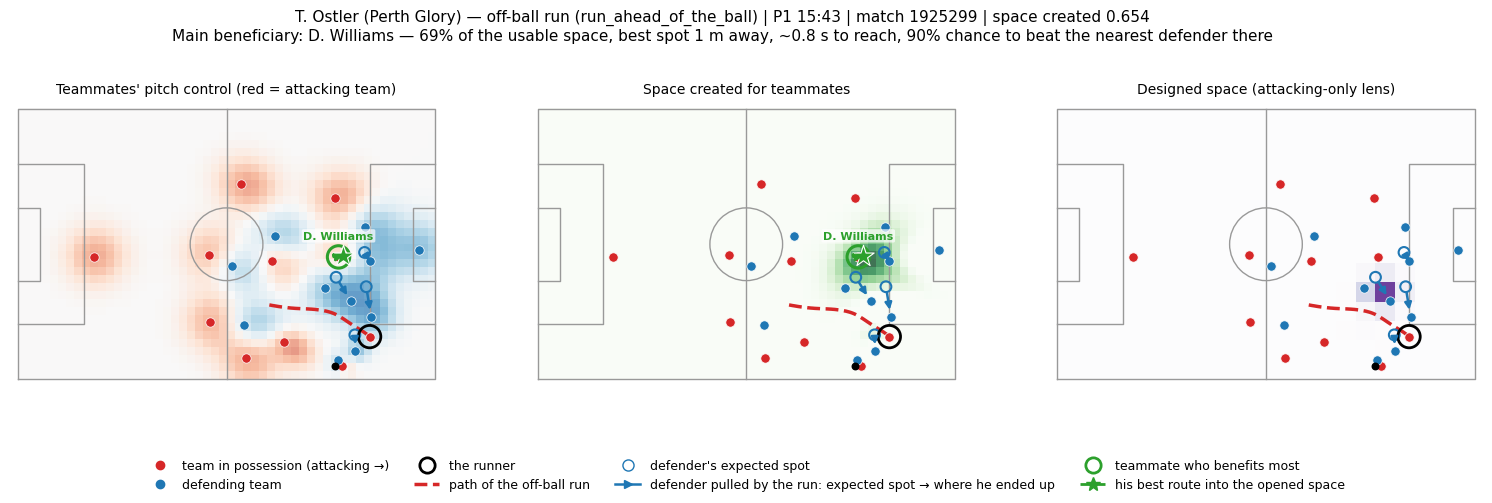

  who benefits from T. Ostler's off-ball run:


,name,benefit,share
3,D. Williams,0.694,0.694
8,A. Faisal,0.151,0.151
2,T. Gomulka,0.128,0.128


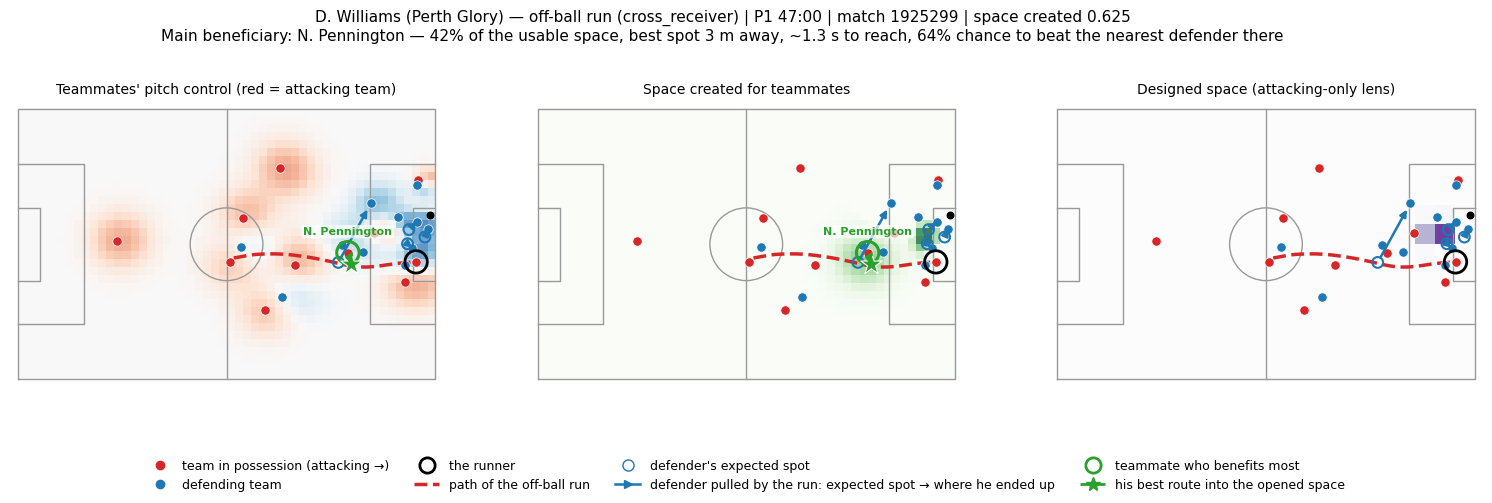

  who benefits from D. Williams's off-ball run:


,name,benefit,share
5,N. Pennington,0.676,0.420
2,T. Gomulka,0.372,0.232
7,A. Bugarija,0.347,0.216


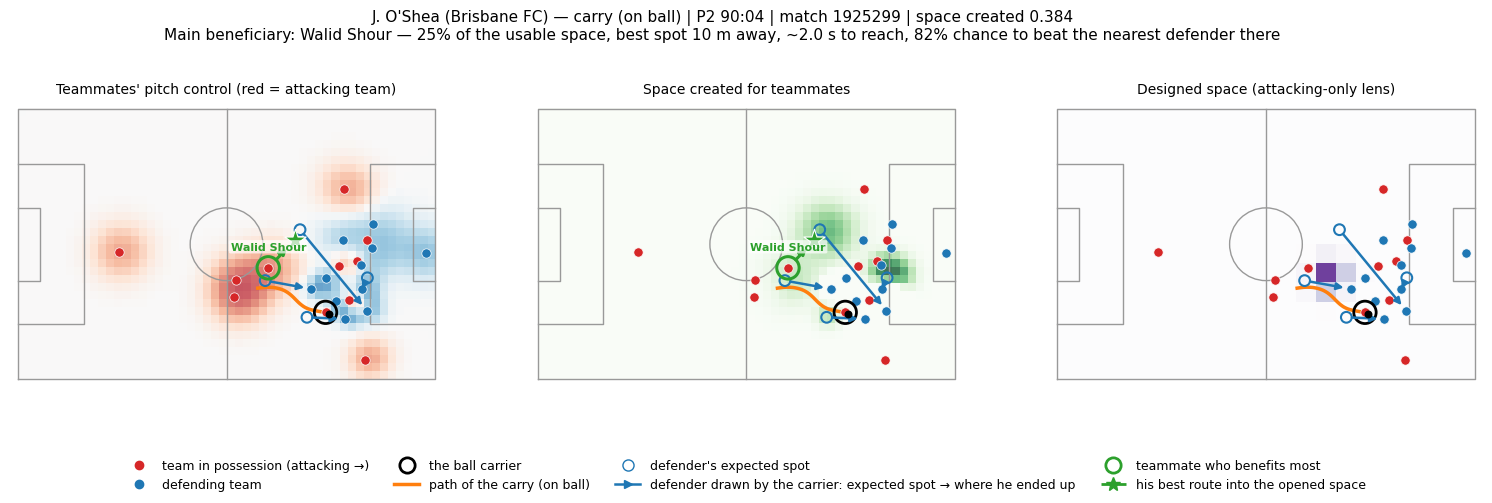

  who benefits from J. O'Shea's carry (on ball):


,name,benefit,share
2,Walid Shour,0.589,0.245
8,J. Brazete,0.397,0.165
6,Q. MacNicol,0.323,0.134


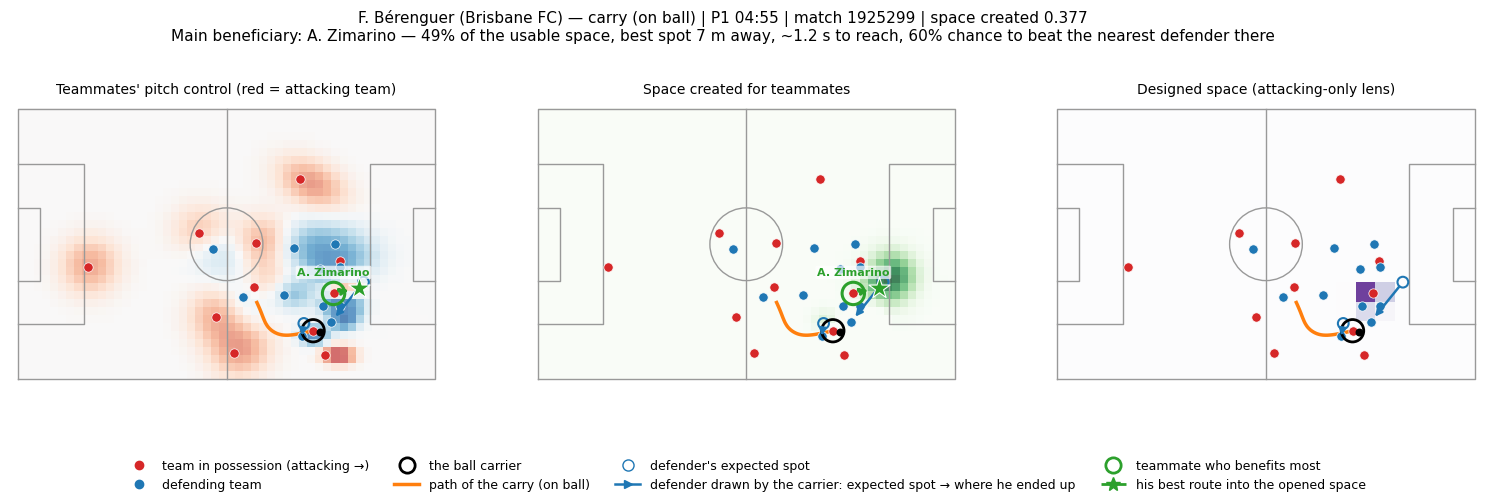

  who benefits from F. Bérenguer's carry (on ball):


,name,benefit,share
7,A. Zimarino,0.403,0.490
6,T. Waddingham,0.385,0.469
5,K. Jelacic,0.020,0.024


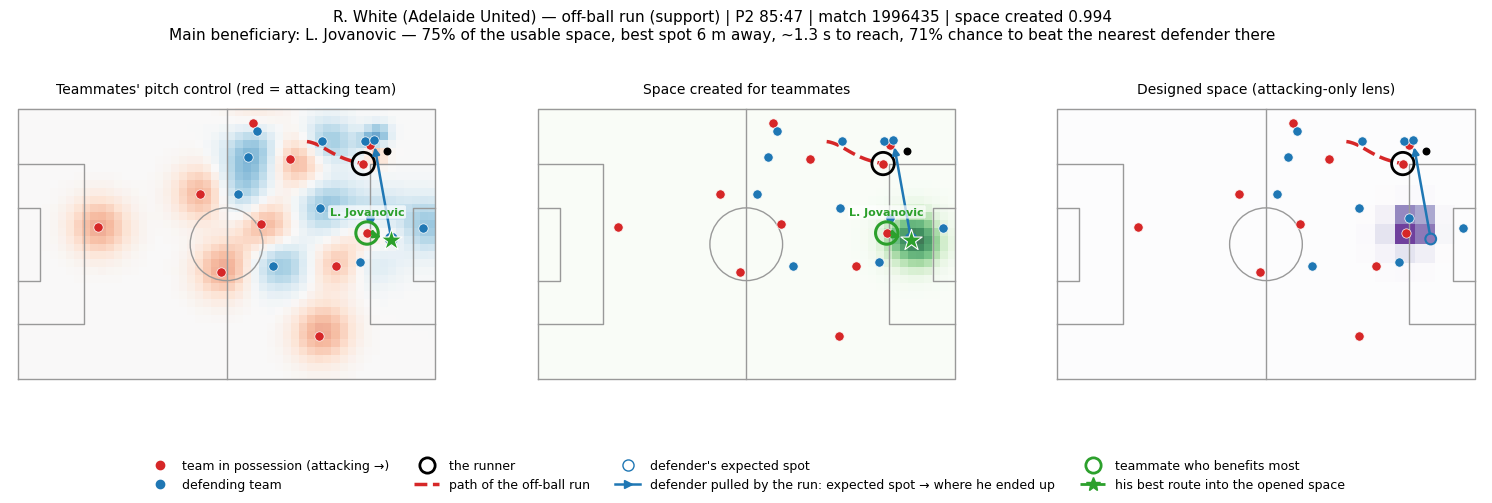

  who benefits from R. White's off-ball run:


,name,benefit,share
5,L. Jovanovic,1.071,0.746
6,A. Ayoubi,0.327,0.228
1,Y. Dukuly,0.028,0.020


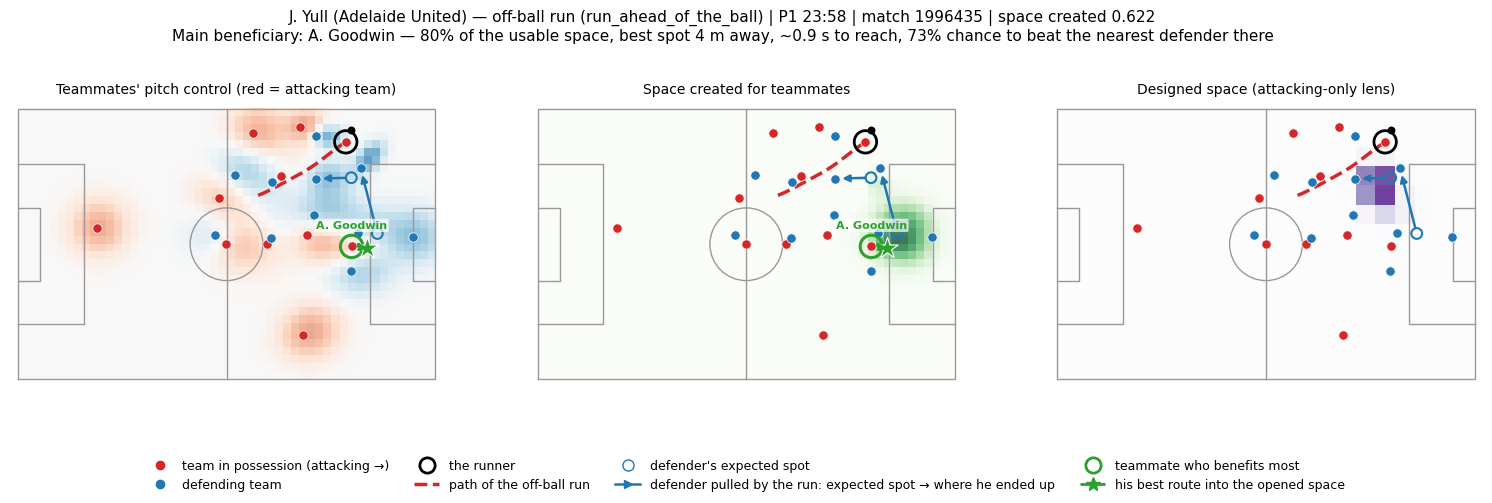

  who benefits from J. Yull's off-ball run:


,name,benefit,share
5,A. Goodwin,0.718,0.804
3,S. Mauk,0.149,0.167
6,E. Alagich,0.012,0.014


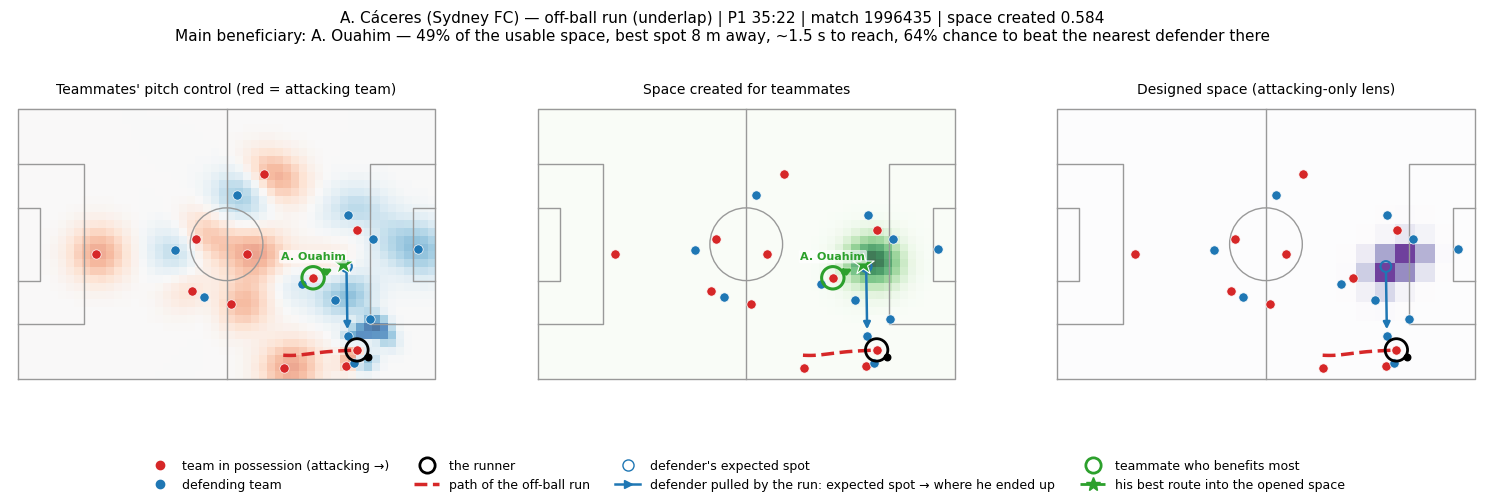

  who benefits from A. Cáceres's off-ball run:


,name,benefit,share
2,A. Ouahim,0.512,0.487
0,P. Klimala,0.496,0.472
6,C. Hollman,0.019,0.018


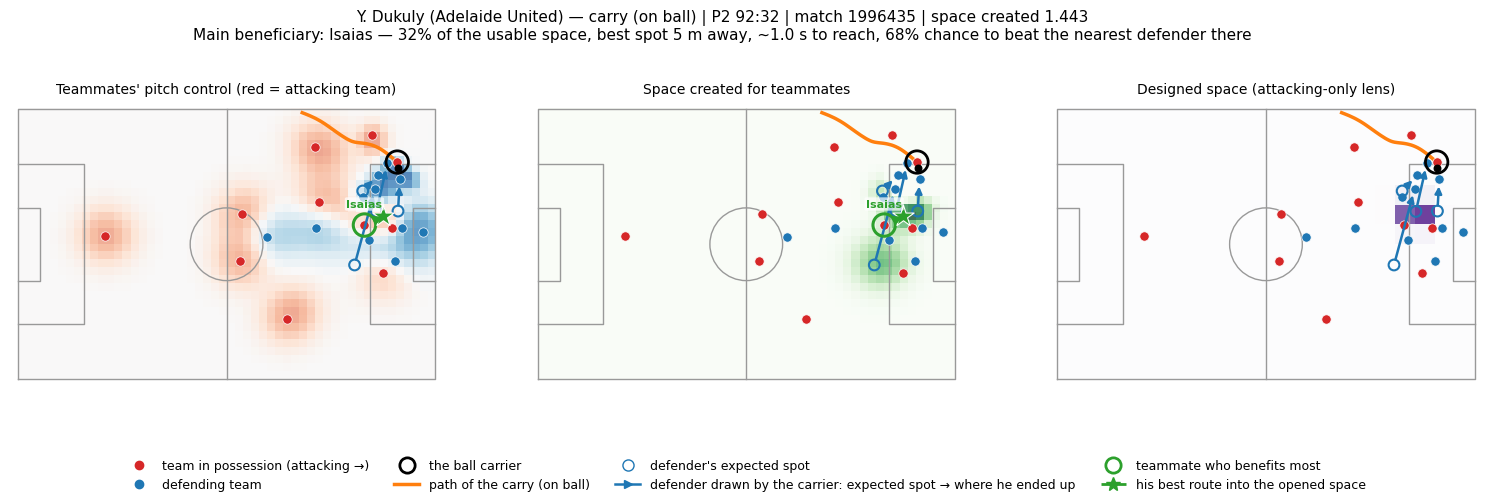

  who benefits from Y. Dukuly's carry (on ball):


,name,benefit,share
3,Isaias,1.037,0.320
5,A. Ayoubi,0.876,0.270
4,L. Jovanovic,0.800,0.247


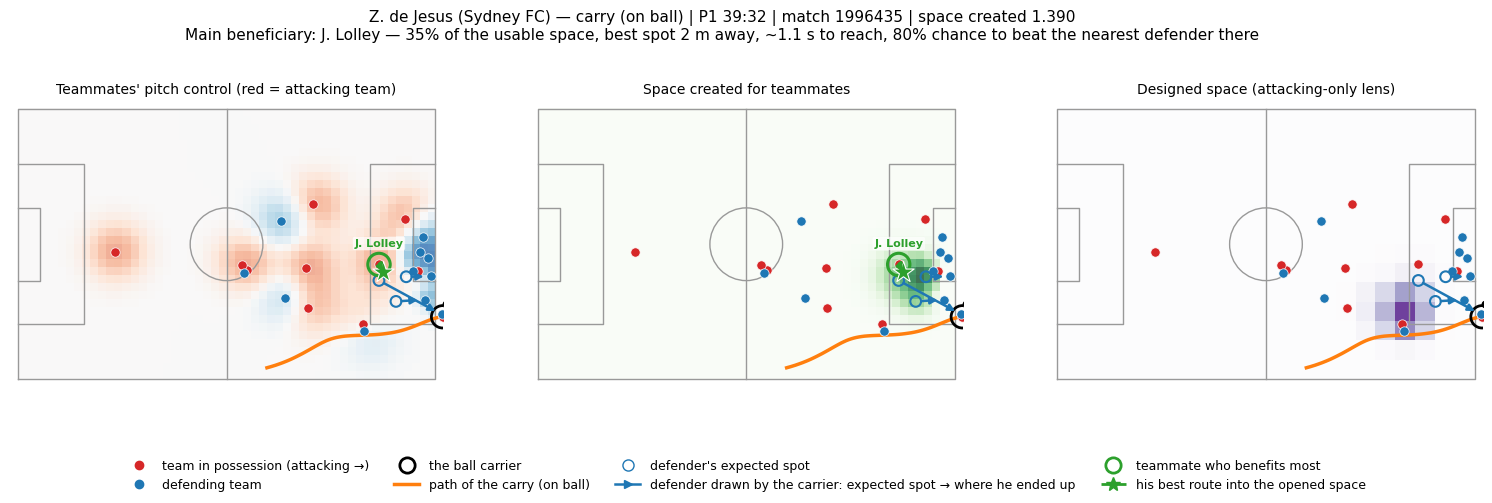

  who benefits from Z. de Jesus's carry (on ball):


,name,benefit,share
1,J. Lolley,1.512,0.353
2,A. Ouahim,1.184,0.276
5,A. Cáceres,0.744,0.174


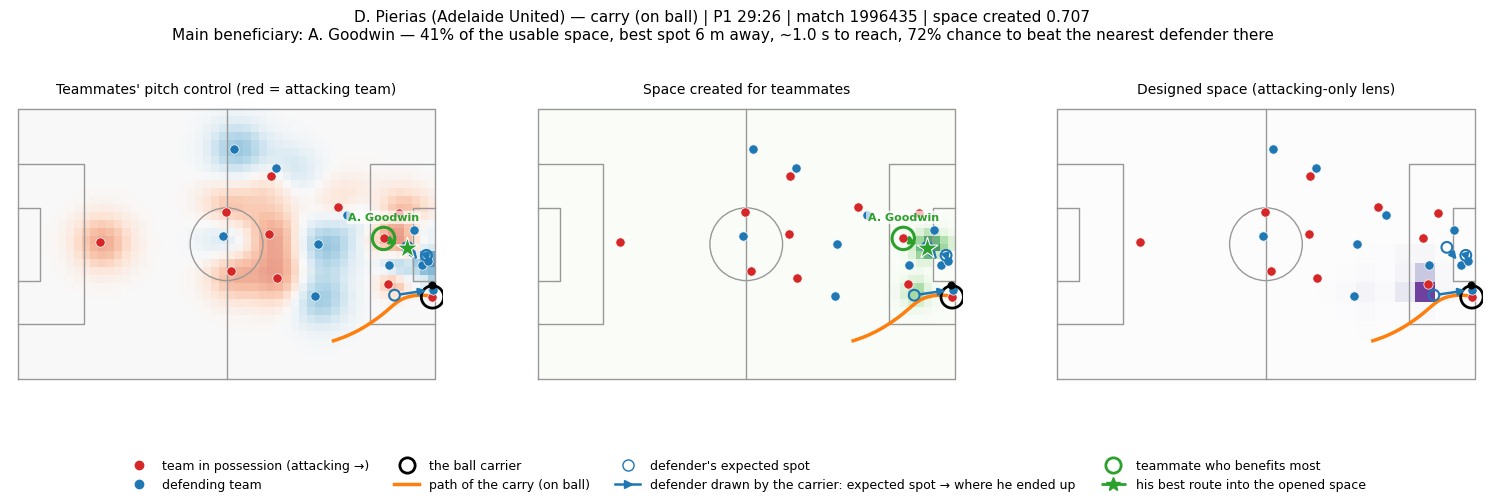

  who benefits from D. Pierias's carry (on ball):


,name,benefit,share
5,A. Goodwin,0.564,0.411
1,Z. Clough,0.477,0.348
3,S. Mauk,0.304,0.222


,match_id,kind,player,clock,frame_start,created,run_type,beneficiary,beneficiary_share,gif
7,1996435,carry,Y. Dukuly,P2 92:27,56503,1.4429,carry (on ball),Isaias,0.32,carry_1996435_56556.gif
8,1996435,carry,Z. de Jesus,P1 39:25,23660,1.3904,carry (on ball),J. Lolley,0.35,carry_1996435_23737.gif
4,1996435,off_ball,R. White,P2 85:45,52481,0.9942,support,L. Jovanovic,0.75,off_ball_1996435_52509.gif
9,1996435,carry,D. Pierias,P1 29:21,17624,0.7066,carry (on ball),A. Goodwin,0.41,carry_1996435_17672.gif
0,1925299,off_ball,T. Ostler,P1 15:37,9384,0.6544,run_ahead_of_the_ball,D. Williams,0.69,off_ball_1925299_9441.gif
1,1925299,off_ball,D. Williams,P1 46:52,28131,0.6249,cross_receiver,N. Pennington,0.42,off_ball_1925299_28211.gif
5,1996435,off_ball,J. Yull,P1 23:54,14356,0.6225,run_ahead_of_the_ball,A. Goodwin,0.80,off_ball_1996435_14396.gif
6,1996435,off_ball,A. Cáceres,P1 35:19,21209,0.5845,underlap,A. Ouahim,0.49,off_ball_1996435_21233.gif
2,1925299,carry,J. O'Shea,P2 89:59,57243,0.3838,carry (on ball),Walid Shour,0.25,carry_1925299_57292.gif
3,1925299,carry,F. Bérenguer,P1 04:51,2929,0.3769,carry (on ball),A. Zimarino,0.49,carry_1925299_2964.gif


In [32]:
cases = pick_cases(R, n=10)
print(cases.kind.value_counts().to_string())
index_rows = []
for mid, group in cases.groupby("match_id"):
    ctx = build_ctx(mid)                        # load each match once
    for run in group.itertuples():
        _, ben = plot_run_case(run, ctx)
        gif = animate_run(run, ctx)
        if ben is not None:
            print(f"  who benefits from {mins['name'].get(run.player_id, run.player_id)}'s {KIND_STYLE[run.kind]['label']}:")
            display(ben["ranking"].head(3)[["name", "benefit", "share"]].round(3))
        index_rows.append(dict(match_id=mid, kind=run.kind, player=mins["name"].get(run.player_id, run.player_id),
                               clock=match_clock(ctx.trk, int(run.idx_start)), frame_start=run.frame_start,
                               created=round(run.created, 4), run_type=run.run_type,
                               beneficiary=ben["name"] if ben else None,
                               beneficiary_share=round(ben["share"], 2) if ben else None, gif=gif.name))
case_index = pd.DataFrame(index_rows).sort_values("created", ascending=False)
case_index.to_csv(FIG_DIR / "cases" / "case_index.csv", index=False)
display(case_index)

## 17. Next steps

* **Refactor into `src/`** — sections 2, 4–11 map directly onto modules (`data`, `value`, `pitch_control`,
  `baseline`, `runs`, `metrics`, `line`), which is what the Cup's reusability criterion rewards.
* **Sensitivity checks** — vary `CF_BANDWIDTH`, the drag thresholds, `PC_OPEN` and the value surface
  (fitted vs parametric) and confirm the leaderboards are stable.
* **Credit sharing** — when several runs happen at once, split created space by each runner's share of the
  dragged defenders (Shapley-style) instead of crediting each run independently.
* **Pose** — run Section 13 on both full pose matches; compare decoy vs genuine runs by orientation.
* **Footage** — use the match clocks on the case-study figures to pull matching broadcast clips (check the
  competition rules and rights first).